# Phân tích các yếu tố ảnh hưởng đến rating người dùng trên MovieLens bằng cách kết hợp dữ liệu thông tin phim (TMDb)

In [100]:
import pandas as pd
import numpy as np
import re
import json
import ast
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import warnings

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MultiLabelBinarizer
from sklearn.cluster import KMeans, DBSCAN
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, silhouette_score, accuracy_score

import xgboost as xgb
import shap
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score


In [101]:
warnings.filterwarnings('ignore')

# --- 1. ĐỊNH NGHĨA HÀM XỬ LÝ ---
def clean_movielens_title(text):
    return re.sub(r'\s*\(\d{4}\)$', '', str(text)).lower().strip()

def clean_tmdb_title(text):
    return str(text).lower().strip()

def get_director(text):
    try:
        data = ast.literal_eval(text)
        for x in data:
            if x['job'] == 'Director': return x['name']
        return np.nan
    except: return np.nan

def get_top_actors(text):
    try:
        data = ast.literal_eval(text)
        return [x['name'] for x in data[:3]]
    except: return []

## Chuẩn bị Dữ liệu (Data Preparation)

In [102]:
# --- 2. TẢI DỮ LIỆU ---
print("Đang tải dữ liệu...")
u_cols = ['UserID', 'Gender', 'Age', 'Occupation', 'Zip-code']
m_cols = ['MovieID', 'Title', 'Genres']
r_cols = ['UserID', 'MovieID', 'Rating', 'Timestamp']

users = pd.read_csv('datasets/movie_len_1M/users.dat', sep='::', names=u_cols, encoding='latin-1', engine='python')
movies = pd.read_csv('datasets/movie_len_1M/movies.dat', sep='::', names=m_cols, encoding='latin-1', engine='python')
ratings = pd.read_csv('datasets/movie_len_1M/ratings.dat', sep='::', names=r_cols, encoding='latin-1', engine='python')

# --- TÍNH ĐIỂM TRUNG BÌNH (AVG_RATING) ---
print("Đang tính toán điểm trung bình cho từng phim...")
movie_targets = ratings.groupby('MovieID')['Rating'].mean().reset_index()
movie_targets.columns = ['MovieID', 'avg_rating']

Đang tải dữ liệu...
Đang tính toán điểm trung bình cho từng phim...


In [103]:
users.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6040 entries, 0 to 6039
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   UserID      6040 non-null   int64 
 1   Gender      6040 non-null   object
 2   Age         6040 non-null   int64 
 3   Occupation  6040 non-null   int64 
 4   Zip-code    6040 non-null   object
dtypes: int64(3), object(2)
memory usage: 236.1+ KB


**Các ý nghĩa của từng cột trong bảng Users**:
| Cột (Column)   | Ý nghĩa |
|----------------|---------|
| **UserID**     | Mã định danh của người dùng (ID duy nhất). |
| **Gender**     | Giới tính của người dùng (M/F). |
| **Age**        | Nhóm tuổi hoặc mã tuổi của người dùng (ví dụ: 1 = dưới 18, 18, 25, 35...). |
| **Occupation** | Mã nghề nghiệp của người dùng (một số nguyên biểu diễn từng loại nghề khác nhau). |
| **Zip-code**   | Mã bưu điện (ZIP) hoặc khu vực mà người dùng sinh sống. |


In [104]:
movies.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3883 entries, 0 to 3882
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   MovieID  3883 non-null   int64 
 1   Title    3883 non-null   object
 2   Genres   3883 non-null   object
dtypes: int64(1), object(2)
memory usage: 91.1+ KB


**Các ý nghĩa của từng cột trong bảng Movies**:
| Cột (Column) | Ý nghĩa |
|--------------|---------|
| **MovieID**  | ID duy nhất của phim trong hệ thống MovieLens. |
| **Title**    | Tên phim kèm năm phát hành (ví dụ: *Toy Story (1995)*). |
| **Genres**   | Các thể loại phim, phân tách bằng dấu `|` (ví dụ: *Animation|Children's|Comedy*). |


In [105]:
ratings.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000209 entries, 0 to 1000208
Data columns (total 4 columns):
 #   Column     Non-Null Count    Dtype
---  ------     --------------    -----
 0   UserID     1000209 non-null  int64
 1   MovieID    1000209 non-null  int64
 2   Rating     1000209 non-null  int64
 3   Timestamp  1000209 non-null  int64
dtypes: int64(4)
memory usage: 30.5 MB


**Các ý nghĩa của từng cột trong bảng Ratings**:
| Cột (Column) | Ý nghĩa |
|--------------|---------|
| **UserID**   | ID người dùng đã đánh giá phim. |
| **MovieID**  | ID của bộ phim được đánh giá. |
| **Rating**   | Điểm đánh giá do người dùng chấm (thường từ 1 đến 5). |
| **Timestamp**| Thời điểm đánh giá (dạng UNIX timestamp – số giây tính từ 1/1/1970). |


In [106]:
# --- 3. XỬ LÝ DỮ LIỆU TMDB ---
try:
    tmdb_cred = pd.read_csv('datasets/tmdb_5000/tmdb_5000_credits.csv', encoding='utf-8')
    tmdb_mov = pd.read_csv('datasets/tmdb_5000/tmdb_5000_movies.csv', encoding='utf-8')
except:
    tmdb_cred = pd.read_csv('datasets/tmdb_5000/tmdb_5000_credits.csv', encoding='latin-1')
    tmdb_mov = pd.read_csv('datasets/tmdb_5000/tmdb_5000_movies.csv', encoding='latin-1')

tmdb_cred.columns = ['movie_id', 'title', 'cast', 'crew']
tmdb_mov = tmdb_mov.rename(columns={'id': 'movie_id'})
tmdb_full = pd.merge(tmdb_mov, tmdb_cred, on='movie_id')

print(f"Loaded & Merged TMDB: {tmdb_full.shape}")

Loaded & Merged TMDB: (4803, 23)


In [107]:
tmdb_full.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4803 entries, 0 to 4802
Data columns (total 23 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   budget                4803 non-null   int64  
 1   genres                4803 non-null   object 
 2   homepage              1712 non-null   object 
 3   movie_id              4803 non-null   int64  
 4   keywords              4803 non-null   object 
 5   original_language     4803 non-null   object 
 6   original_title        4803 non-null   object 
 7   overview              4800 non-null   object 
 8   popularity            4803 non-null   float64
 9   production_companies  4803 non-null   object 
 10  production_countries  4803 non-null   object 
 11  release_date          4802 non-null   object 
 12  revenue               4803 non-null   int64  
 13  runtime               4801 non-null   float64
 14  spoken_languages      4803 non-null   object 
 15  status               

**Giải thích ý nghĩa của các cột**
| Cột (Column)           | Ý nghĩa |
|------------------------|---------|
| **budget**             | Ngân sách sản xuất phim (USD). |
| **genres**             | Thể loại phim, lưu dưới dạng chuỗi JSON (Action, Comedy…). |
| **homepage**           | Trang web chính thức của bộ phim. |
| **movie_id**           | ID phim trong cơ sở dữ liệu TheMovieDB. |
| **keywords**           | Các từ khóa mô tả nội dung phim. |
| **original_language**  | Ngôn ngữ gốc của phim (ví dụ: `en`, `fr`). |
| **original_title**     | Tên gốc của bộ phim. |
| **overview**           | Tóm tắt nội dung phim. |
| **popularity**         | Mức độ phổ biến của phim trên TMDB. |
| **production_companies** | Danh sách công ty sản xuất phim (JSON string). |
| **production_countries** | Danh sách quốc gia sản xuất phim. |
| **release_date**       | Ngày phát hành phim. |
| **revenue**            | Doanh thu phòng vé (USD). |
| **runtime**            | Thời lượng phim (phút). |
| **spoken_languages**   | Danh sách ngôn ngữ được sử dụng trong phim. |
| **status**             | Tình trạng phát hành (Released, Post Production…). |
| **tagline**            | Slogan/tagline của phim. |
| **title**              | Tên phim phát hành chính thức. |
| **vote_average**       | Điểm đánh giá trung bình trên TMDB. |
| **vote_count**         | Số lượt đánh giá. |
| **tittle_credits**     | Thông tin credit khi merge, có thể là lỗi chính tả của `title_credits`. |
| **cast**               | Danh sách diễn viên của phim (JSON string). |
| **crew**               | Danh sách nhân sự (đạo diễn, biên kịch…) của phim (JSON string). |


In [108]:
# --- 3. HIỂN THỊ DỮ LIỆU MẪU ĐỂ KIỂM TRA ---

print("\n--- Sample Users ---")
users.head(3)


--- Sample Users ---


,UserID,Gender,Age,Occupation,Zip-code
0,1,F,1,10,48067
1,2,M,56,16,70072
2,3,M,25,15,55117


In [109]:
print("\n--- Sample Movies ---")
movies.head(3)


--- Sample Movies ---


,MovieID,Title,Genres
0,1,Toy Story (1995),Animation|Children's|Comedy
1,2,Jumanji (1995),Adventure|Children's|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance


In [110]:
print("\n--- Sample Ratings ---")
ratings.head(3)


--- Sample Ratings ---


,UserID,MovieID,Rating,Timestamp
0,1,1193,5,978300760
1,1,661,3,978302109
2,1,914,3,978301968


In [111]:
print("\n--- Sample TMDB Credits ---")
tmdb_cred.head(3)


--- Sample TMDB Credits ---


,movie_id,title,cast,crew
0,19995,Avatar,"[{""cast_id"": 242, ""character"": ""Jake Sully"", ""...","[{""credit_id"": ""52fe48009251416c750aca23"", ""de..."
1,285,Pirates of the Caribbean: At World's End,"[{""cast_id"": 4, ""character"": ""Captain Jack Spa...","[{""credit_id"": ""52fe4232c3a36847f800b579"", ""de..."
2,206647,Spectre,"[{""cast_id"": 1, ""character"": ""James Bond"", ""cr...","[{""credit_id"": ""54805967c3a36829b5002c41"", ""de..."


In [112]:
print("\n--- Sample TMDB Movies ---")
tmdb_mov.head(3)


--- Sample TMDB Movies ---


,budget,genres,homepage,movie_id,keywords,original_language,original_title,overview,popularity,production_companies,production_countries,release_date,revenue,runtime,spoken_languages,status,tagline,title,vote_average,vote_count
0,237000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...",http://www.avatarmovie.com/,19995,"[{""id"": 1463, ""name"": ""culture clash""}, {""id"":...",en,Avatar,"In the 22nd century, a paraplegic Marine is di...",150.437577,"[{""name"": ""Ingenious Film Partners"", ""id"": 289...","[{""iso_3166_1"": ""US"", ""name"": ""United States o...",2009-12-10,2787965087,162.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}, {""iso...",Released,Enter the World of Pandora.,Avatar,7.2,11800
1,300000000,"[{""id"": 12, ""name"": ""Adventure""}, {""id"": 14, ""...",http://disney.go.com/disneypictures/pirates/,285,"[{""id"": 270, ""name"": ""ocean""}, {""id"": 726, ""na...",en,Pirates of the Caribbean: At World's End,"Captain Barbossa, long believed to be dead, ha...",139.082615,"[{""name"": ""Walt Disney Pictures"", ""id"": 2}, {""...","[{""iso_3166_1"": ""US"", ""name"": ""United States o...",2007-05-19,961000000,169.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Released,"At the end of the world, the adventure begins.",Pirates of the Caribbean: At World's End,6.9,4500
2,245000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...",http://www.sonypictures.com/movies/spectre/,206647,"[{""id"": 470, ""name"": ""spy""}, {""id"": 818, ""name...",en,Spectre,A cryptic message from Bond’s past sends him o...,107.376788,"[{""name"": ""Columbia Pictures"", ""id"": 5}, {""nam...","[{""iso_3166_1"": ""GB"", ""name"": ""United Kingdom""...",2015-10-26,880674609,148.0,"[{""iso_639_1"": ""fr"", ""name"": ""Fran\u00e7ais""},...",Released,A Plan No One Escapes,Spectre,6.3,4466


## Tiền xử lý dữ liệu (Data Preprocessing)

### Chuẩn hóa (Data Normalization)

In [113]:
# --- 3. XỬ LÝ DỮ LIỆU TMDB (SỬA LẠI ĐỂ TRÁNH LỖI TITLE) ---
print("Đang tải và xử lý TMDB...")
try:
    tmdb_cred = pd.read_csv('datasets/tmdb_5000/tmdb_5000_credits.csv', encoding='utf-8')
    tmdb_mov = pd.read_csv('datasets/tmdb_5000/tmdb_5000_movies.csv', encoding='utf-8')
except:
    tmdb_cred = pd.read_csv('datasets/tmdb_5000/tmdb_5000_credits.csv', encoding='latin-1')
    tmdb_mov = pd.read_csv('datasets/tmdb_5000/tmdb_5000_movies.csv', encoding='latin-1')

# --- ĐIỂM SỬA QUAN TRỌNG TẠI ĐÂY ---
# Đổi tên cột title của credits thành 'tittle_cr' để không trùng với 'title' của bảng movies
tmdb_cred.columns = ['movie_id', 'tittle_cr', 'cast', 'crew'] 

tmdb_mov = tmdb_mov.rename(columns={'id': 'movie_id'})

# Merge nội bộ TMDB
tmdb_full = pd.merge(tmdb_mov, tmdb_cred, on='movie_id')

# Kiểm tra xem cột title có tồn tại không
if 'title' not in tmdb_full.columns:
    # Trường hợp file gốc dùng 'original_title', ta tạo lại cột title
    if 'original_title' in tmdb_full.columns:
        tmdb_full['title'] = tmdb_full['original_title']

print(f"Cột trong TMDB Full: {list(tmdb_full.columns)}") 
# Bây giờ chắc chắn đã có cột 'title'

# --- 4. MERGE METADATA (CHẠY LẠI BƯỚC NÀY SẼ KHÔNG CÒN LỖI) ---
print("Đang xử lý Metadata phim...")

# Tạo khóa nối
movies['title_join'] = movies['Title'].apply(clean_movielens_title)
tmdb_full['title_join'] = tmdb_full['title'].apply(clean_tmdb_title)

# Ghép Movies gốc với TMDB
movies_meta = pd.merge(movies, tmdb_full, on='title_join', how='inner')

# Ghép thêm cột avg_rating (từ bảng movie_targets đã tạo ở bước trước)
movies_meta = pd.merge(movies_meta, movie_targets, on='MovieID', how='inner')

# Trích xuất Director, Actors, Year
movies_meta['director'] = movies_meta['crew'].apply(get_director)
movies_meta['actors_temp'] = movies_meta['cast'].apply(get_top_actors)
actors_df = movies_meta['actors_temp'].apply(pd.Series).iloc[:, :3]
actors_df.columns = ['actor_1', 'actor_2', 'actor_3']
movies_meta = pd.concat([movies_meta, actors_df], axis=1)
movies_meta['release_year'] = movies_meta['Title'].str.extract(r'\((\d{4})\)$').astype(float)

# Chọn lọc các cột metadata
cols_meta = [
    'MovieID', 'Title', 'Genres', 'release_year', 'avg_rating', 
    'director', 'actor_1', 'actor_2', 'actor_3',
    'budget', 'revenue', 'vote_average', 'vote_count', 'runtime'
]
movies_final_meta = movies_meta[cols_meta]

# --- 5. TẠO DATAFRAME CUỐI CÙNG ---
print("Đang ghép vào bảng Ratings gốc...")
df_final = pd.merge(ratings, movies_final_meta, on='MovieID', how='inner')

print("-" * 30)
print(f"Kích thước cuối cùng: {df_final.shape}")
print("5 dòng đầu tiên:")
print(df_final[['UserID', 'Title', 'Rating', 'avg_rating', 'vote_average']].head())

Đang tải và xử lý TMDB...
Cột trong TMDB Full: ['budget', 'genres', 'homepage', 'movie_id', 'keywords', 'original_language', 'original_title', 'overview', 'popularity', 'production_companies', 'production_countries', 'release_date', 'revenue', 'runtime', 'spoken_languages', 'status', 'tagline', 'title', 'vote_average', 'vote_count', 'tittle_cr', 'cast', 'crew']
Đang xử lý Metadata phim...
Đang ghép vào bảng Ratings gốc...
------------------------------
Kích thước cuối cùng: (450575, 17)
5 dòng đầu tiên:
   UserID                                   Title  Rating  avg_rating  \
0       1  One Flew Over the Cuckoo's Nest (1975)       5    4.390725   
1       1                     My Fair Lady (1964)       3    4.154088   
2       1                  Erin Brockovich (2000)       4    3.863878   
3       1                          Ben-Hur (1959)       5    4.110795   
4       1  Snow White and the Seven Dwarfs (1937)       4    3.845347   

   vote_average  
0           8.2  
1           7.4 

### Trích xuất đặc trưng (Feature Selection)

In [114]:
movies_merged = movies_meta.copy()

# --- 2. ÁP DỤNG VÀO DATAFRAME ---
print("Đang trích xuất dữ liệu Đạo diễn, Diễn viên và Năm phát hành...")

# 1. Reset các cột nếu đã lỡ chạy trước đó (để tránh lỗi duplicate columns)
cols_to_reset = ['director', 'actor_1', 'actor_2', 'actor_3', 'actors_list', 'release_year']
movies_merged = movies_merged.drop(columns=[c for c in cols_to_reset if c in movies_merged.columns], errors='ignore')

# 2. Trích xuất Đạo diễn (Director)
# Lưu ý: Hàm get_director phải được định nghĩa từ trước
movies_merged['director'] = movies_merged['crew'].apply(get_director)

# 3. Trích xuất Diễn viên (Actors) - CÁCH TỐI ƯU & AN TOÀN HƠN
# Lấy list diễn viên
movies_merged['actors_list'] = movies_merged['cast'].apply(get_top_actors)

# Tách list thành các cột riêng biệt
actors_df = movies_merged['actors_list'].apply(pd.Series)

# Đảm bảo luôn có đủ 3 cột (0, 1, 2) dù dữ liệu thiếu
for i in range(3):
    if i not in actors_df.columns:
        actors_df[i] = np.nan

# Chỉ lấy 3 cột đầu tiên và đổi tên
actors_df = actors_df.iloc[:, :3]
actors_df.columns = ['actor_1', 'actor_2', 'actor_3']

# Ghép vào bảng chính
movies_merged = pd.concat([movies_merged, actors_df], axis=1)

# 4. Trích xuất Năm phát hành (Release Year) từ Title của MovieLens
# Regex: Tìm 4 số nằm trong ngoặc đơn ở cuối chuỗi
movies_merged['release_year'] = movies_merged['Title'].str.extract(r'\((\d{4})\)$')
movies_merged['release_year'] = pd.to_numeric(movies_merged['release_year'], errors='coerce')

# 5. Dọn dẹp cột tạm
movies_merged = movies_merged.drop(columns=['actors_list'], errors='ignore')

# --- 3. KIỂM TRA KẾT QUẢ ---
print("-" * 30)
print("Các cột hiện có sau khi xử lý Feature Engineering:")
print(list(movies_merged.columns))

print("\n5 dòng dữ liệu mẫu (Kiểm tra Đạo diễn, Diễn viên, Năm):")
cols_check = ['Title', 'release_year', 'director', 'actor_1', 'Genres']
print(movies_merged[cols_check].head())

Đang trích xuất dữ liệu Đạo diễn, Diễn viên và Năm phát hành...
------------------------------
Các cột hiện có sau khi xử lý Feature Engineering:
['MovieID', 'Title', 'Genres', 'title_join', 'budget', 'genres', 'homepage', 'movie_id', 'keywords', 'original_language', 'original_title', 'overview', 'popularity', 'production_companies', 'production_countries', 'release_date', 'revenue', 'runtime', 'spoken_languages', 'status', 'tagline', 'title', 'vote_average', 'vote_count', 'tittle_cr', 'cast', 'crew', 'avg_rating', 'actors_temp', 'director', 'actor_1', 'actor_2', 'actor_3', 'release_year']

5 dòng dữ liệu mẫu (Kiểm tra Đạo diễn, Diễn viên, Năm):
                     Title  release_year         director          actor_1  \
0         Toy Story (1995)          1995    John Lasseter        Tom Hanks   
1         GoldenEye (1995)          1995  Martin Campbell   Pierce Brosnan   
2             Nixon (1995)          1995     Oliver Stone  Anthony Hopkins   
3  Cutthroat Island (1995)        

### Tích hợp dữ liệu (Data Integration)

In [115]:
# --- TỐI ƯU HÓA TRƯỚC KHI MERGE ---

# 1. Chọn lọc các cột cần thiết từ bảng phim (Metadata)
# Chúng ta chỉ giữ lại những thông tin có giá trị phân tích
cols_to_keep = [
    'MovieID', 'Title',             # Định danh phim
    'Genres', 'release_year',       # Thông tin cơ bản
    'director', 'actor_1', 'actor_2', 'actor_3', # Ekip làm phim
    'budget', 'revenue',            # Tài chính
    'vote_average', 'vote_count',   # Đánh giá từ TMDB
    'avg_rating',                    # Đánh giá trung bình từ MovieLens (Đã tính ở bước trước)
    'runtime'
]

# Lọc để chỉ lấy các cột thực sự tồn tại trong movies_merged (tránh lỗi nếu thiếu cột nào đó)
existing_cols = [c for c in cols_to_keep if c in movies_merged.columns]
movies_lean = movies_merged[existing_cols]

# 2. Thực hiện Merge cuối cùng (Big Merge)
# Ghép bảng Ratings (1 triệu dòng) với bảng Metadata phim đã lọc gọn
# Dùng 'inner' để chỉ giữ lại các rating của những phim ĐÃ CÓ thông tin từ TMDB
print("Đang thực hiện ghép dữ liệu cuối cùng (sẽ mất một chút thời gian)...")
full_data = pd.merge(ratings, movies_lean, on='MovieID', how='inner')

# --- 3. KIỂM TRA KẾT QUẢ ---
print("-" * 30)
print(f"Tổng số lượt đánh giá gốc (Ratings): {ratings.shape[0]}")
print(f"Tổng số dòng dữ liệu sau khi merge (Full Data): {full_data.shape[0]}")
print(f"-> Số lượng đánh giá bị loại bỏ (do phim không khớp TMDB): {ratings.shape[0] - full_data.shape[0]}")
print("-" * 30)

# Xem 5 dòng dữ liệu hoàn chỉnh để đảm bảo bạn có đủ 3 loại điểm số
# 1. Rating: Điểm do người dùng này chấm
# 2. avg_rating: Điểm trung bình của phim trên MovieLens
# 3. vote_average: Điểm trung bình của phim trên TMDB
print("5 dòng dữ liệu mẫu (Check đủ 3 cột điểm):")
cols_check = ['UserID', 'Title', 'Rating', 'avg_rating', 'vote_average', 'director']
print(full_data[cols_check].head())

Đang thực hiện ghép dữ liệu cuối cùng (sẽ mất một chút thời gian)...
------------------------------
Tổng số lượt đánh giá gốc (Ratings): 1000209
Tổng số dòng dữ liệu sau khi merge (Full Data): 450575
-> Số lượng đánh giá bị loại bỏ (do phim không khớp TMDB): 549634
------------------------------
5 dòng dữ liệu mẫu (Check đủ 3 cột điểm):
   UserID                                   Title  Rating  avg_rating  \
0       1  One Flew Over the Cuckoo's Nest (1975)       5    4.390725   
1       1                     My Fair Lady (1964)       3    4.154088   
2       1                  Erin Brockovich (2000)       4    3.863878   
3       1                          Ben-Hur (1959)       5    4.110795   
4       1  Snow White and the Seven Dwarfs (1937)       4    3.845347   

   vote_average           director  
0           8.2       Miloš Forman  
1           7.4       George Cukor  
2           7.1  Steven Soderbergh  
3           5.3  Timur Bekmambetov  
4           6.9         David Hand  


In [116]:
full_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 450575 entries, 0 to 450574
Data columns (total 17 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   UserID        450575 non-null  int64  
 1   MovieID       450575 non-null  int64  
 2   Rating        450575 non-null  int64  
 3   Timestamp     450575 non-null  int64  
 4   Title         450575 non-null  object 
 5   Genres        450575 non-null  object 
 6   release_year  450575 non-null  int64  
 7   director      450535 non-null  object 
 8   actor_1       450535 non-null  object 
 9   actor_2       450535 non-null  object 
 10  actor_3       450535 non-null  object 
 11  budget        450575 non-null  int64  
 12  revenue       450575 non-null  int64  
 13  vote_average  450575 non-null  float64
 14  vote_count    450575 non-null  int64  
 15  avg_rating    450575 non-null  float64
 16  runtime       450575 non-null  float64
dtypes: float64(3), int64(8), object(6)
memory usage:

In [117]:
full_data.head(10)

,UserID,MovieID,Rating,Timestamp,Title,Genres,release_year,director,actor_1,actor_2,actor_3,budget,revenue,vote_average,vote_count,avg_rating,runtime
0,1,1193,5,978300760,One Flew Over the Cuckoo's Nest (1975),Drama,1975,Miloš Forman,Jack Nicholson,Louise Fletcher,Danny DeVito,3000000,108981275,8.2,2919,4.390725,133.0
1,1,914,3,978301968,My Fair Lady (1964),Musical|Romance,1964,George Cukor,Audrey Hepburn,Rex Harrison,Stanley Holloway,17000000,72070731,7.4,352,4.154088,170.0
2,1,3408,4,978300275,Erin Brockovich (2000),Drama,2000,Steven Soderbergh,Julia Roberts,Albert Finney,Aaron Eckhart,52000000,256271286,7.1,716,3.863878,131.0
3,1,1287,5,978302039,Ben-Hur (1959),Action|Adventure|Drama,1959,Timur Bekmambetov,Jack Huston,Toby Kebbell,Rodrigo Santoro,100000000,94061311,5.3,621,4.110795,125.0
4,1,594,4,978302268,Snow White and the Seven Dwarfs (1937),Animation|Children's|Musical,1937,David Hand,Adriana Caselotti,Lucille La Verne,Harry Stockwell,1488423,184925486,6.9,1914,3.845347,83.0
5,1,2791,4,978302188,Airplane! (1980),Comedy,1980,Jerry Zucker,Robert Hays,Julie Hagerty,Kareem Abdul-Jabbar,3500000,83453539,7.1,1074,3.971115,88.0
6,1,2018,4,978301777,Bambi (1942),Animation|Children's,1942,David Hand,Donnie Dunagan,Peter Behn,Stan Alexander,858000,267447150,6.8,1405,3.738540,70.0
7,1,2797,4,978302039,Big (1988),Comedy|Fantasy,1988,Penny Marshall,Tom Hanks,Elizabeth Perkins,Robert Loggia,18000000,151668774,6.9,993,3.855801,104.0
8,1,1270,5,978300055,Back to the Future (1985),Comedy|Sci-Fi,1985,Robert Zemeckis,Michael J. Fox,Christopher Lloyd,Lea Thompson,19000000,381109762,8.0,6079,3.990321,116.0
9,1,527,5,978824195,Schindler's List (1993),Drama|War,1993,Steven Spielberg,Liam Neeson,Ben Kingsley,Ralph Fiennes,22000000,321365567,8.3,4329,4.510417,195.0


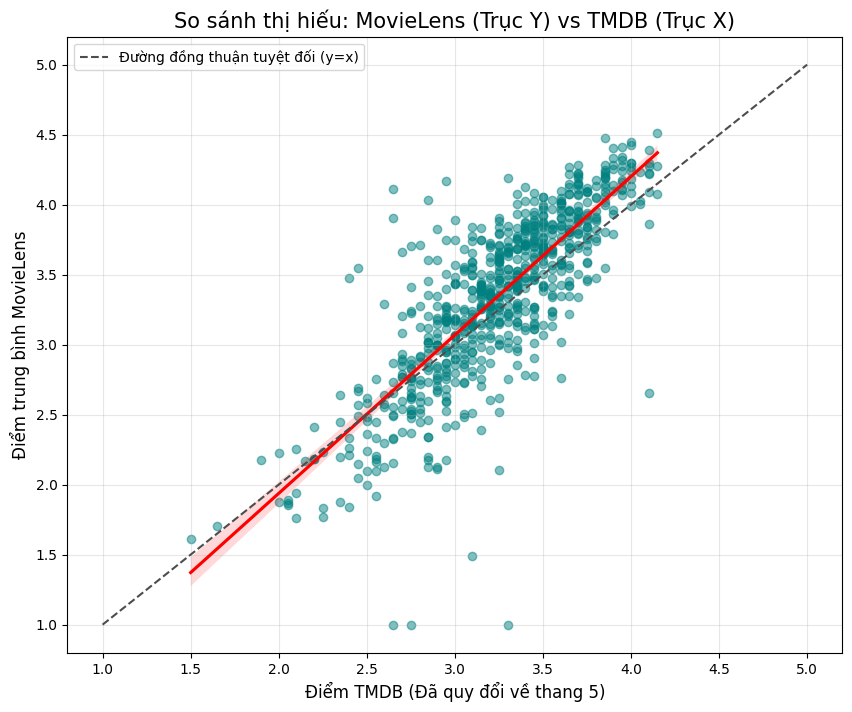

--- PHIM MOVIELENS THÍCH HƠN TMDB (Top 5) ---
                         Title  ML_Score  TMDB_Score_Norm
95              Ben-Hur (1959)  4.110795             2.65
347        Ghostbusters (1984)  3.905548             2.65
701     Shall We Dance? (1937)  4.165714             2.95
29   All the King's Men (1949)  4.033613             2.85
369  Gulliver's Travels (1939)  3.547009             2.45

--- PHIM TMDB THÍCH HƠN MOVIELENS (Top 5) ---
                         Title  ML_Score  TMDB_Score_Norm
834          Underworld (1997)  1.000000             3.30
342         Get Over It (1996)  1.000000             2.75
718           Sleepover (1995)  1.000000             2.65
222  Digimon: The Movie (2000)  1.488372             3.10
628              Psycho (1998)  2.651515             4.10


In [118]:
# --- BƯỚC 1: GOM NHÓM DỮ LIỆU THEO PHIM ---
# Tính điểm trung bình thực tế của người dùng MovieLens cho từng phim
movie_comparison = full_data.groupby('Title').agg({
    'Rating': 'mean',          # Điểm trung bình MovieLens (1-5)
    'vote_average': 'first',   # Điểm TMDB (0-10) - Lấy giá trị đầu tiên vì nó giống nhau cho cả phim
    'vote_count': 'first'   # Lấy số lượng vote để lọc bớt phim ít người xem
}).reset_index()

# Đổi tên cho dễ gọi
movie_comparison.columns = ['Title', 'ML_Score', 'TMDB_Score', 'Vote_Count']

# --- BƯỚC 2: CHUẨN HÓA THANG ĐIỂM ---
# Chuyển TMDB từ thang 10 về thang 5 để so sánh công bằng
movie_comparison['TMDB_Score_Norm'] = movie_comparison['TMDB_Score'] / 2

# Lọc các phim có ít nhất 50 lượt đánh giá để biểu đồ không bị nhiễu
movie_comparison = movie_comparison[movie_comparison['Vote_Count'] > 50]

# --- BƯỚC 3: VẼ BIỂU ĐỒ TƯƠNG QUAN ---
plt.figure(figsize=(10, 8))

# Vẽ Scatter plot kèm đường hồi quy (Regplot)
sns.regplot(x='TMDB_Score_Norm', y='ML_Score', data=movie_comparison,
            scatter_kws={'alpha': 0.5, 'color': 'teal'}, 
            line_kws={'color': 'red'})

# Vẽ đường chéo y=x (Đường tham chiếu sự hoàn hảo)
# Nếu điểm nằm trên đường này: MovieLens và TMDB chấm y hệt nhau
plt.plot([1, 5], [1, 5], ls="--", c=".3", label="Đường đồng thuận tuyệt đối (y=x)")

plt.title('So sánh thị hiếu: MovieLens (Trục Y) vs TMDB (Trục X)', fontsize=15)
plt.xlabel('Điểm TMDB (Đã quy đổi về thang 5)', fontsize=12)
plt.ylabel('Điểm trung bình MovieLens', fontsize=12)
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# --- BƯỚC 4: TÌM NHỮNG PHIM "GÂY TRANH CÃI" NHẤT ---
# Tính độ lệch (Gap)
movie_comparison['Diff'] = movie_comparison['ML_Score'] - movie_comparison['TMDB_Score_Norm']

print("--- PHIM MOVIELENS THÍCH HƠN TMDB (Top 5) ---")
print(movie_comparison.sort_values('Diff', ascending=False)[['Title', 'ML_Score', 'TMDB_Score_Norm']].head(5))

print("\n--- PHIM TMDB THÍCH HƠN MOVIELENS (Top 5) ---")
print(movie_comparison.sort_values('Diff', ascending=True)[['Title', 'ML_Score', 'TMDB_Score_Norm']].head(5))

### Làm sạch dữ liệu (Data Cleaning)

In [119]:
# Kiểm tra dữ liệu bị thiếu (Missing values)
full_data.isnull().sum()

UserID           0
MovieID          0
Rating           0
Timestamp        0
Title            0
Genres           0
release_year     0
director        40
actor_1         40
actor_2         40
actor_3         40
budget           0
revenue          0
vote_average     0
vote_count       0
avg_rating       0
runtime          0
dtype: int64

In [120]:
# XỬ LÝ DỮ LIỆU BỊ THIẾU (XÓA DÒNG)
# inplace=True sẽ thay đổi trực tiếp trên dataframe hiện tại
full_data.dropna(subset=['director', 'actor_1'], inplace=True)

print(f"Đã xóa các dòng Null. Kích thước dữ liệu hiện tại: {full_data.shape}\n Số dòng bị thiếu: \n{full_data.isnull().sum()}")

Đã xóa các dòng Null. Kích thước dữ liệu hiện tại: (450495, 17)
 Số dòng bị thiếu: 
UserID          0
MovieID         0
Rating          0
Timestamp       0
Title           0
Genres          0
release_year    0
director        0
actor_1         0
actor_2         0
actor_3         0
budget          0
revenue         0
vote_average    0
vote_count      0
avg_rating      0
runtime         0
dtype: int64


In [121]:
# Kiểm tra dữ liệu bị trùng lặp
full_data.duplicated().sum()

0

In [122]:
# --- LỌC DỮ LIỆU CHẤT LƯỢNG CAO (CLEANING DATA) ---

print(f"Số lượng dòng dữ liệu ban đầu: {full_data.shape[0]}")

# Áp dụng 3 điều kiện lọc cùng lúc:
# 1. vote_count > 50: Bỏ qua các phim quá ít người quan tâm trên TMDB (tránh nhiễu)
# 2. budget > 10000: Bỏ qua phim không có số liệu ngân sách hoặc ngân sách quá thấp (lỗi nhập liệu)
# 3. revenue > 10000: Bỏ qua phim không có số liệu doanh thu

full_data = full_data[
    (full_data['vote_count'] > 50) & 
    (full_data['budget'] > 10000) & 
    (full_data['revenue'] > 10000)
]

# --- KIỂM TRA KẾT QUẢ SAU KHI LỌC ---
print("-" * 30)
print(f"Số lượng dòng sau khi lọc: {full_data.shape[0]}")
print(f"-> Đã loại bỏ: {full_data.shape[0] - full_data.shape[0]} dòng dữ liệu rác/thiếu thông tin.")

# Xem thống kê nhanh về tài chính của tập dữ liệu sạch
print("\nThống kê dữ liệu tài chính sau khi lọc:")
print(full_data[['budget', 'revenue', 'vote_count']].describe().apply(lambda s: s.apply('{0:.2f}'.format)))

Số lượng dòng dữ liệu ban đầu: 450495
------------------------------
Số lượng dòng sau khi lọc: 397975
-> Đã loại bỏ: 0 dòng dữ liệu rác/thiếu thông tin.

Thống kê dữ liệu tài chính sau khi lọc:
             budget        revenue vote_count
count     397975.00      397975.00  397975.00
mean    37087587.03   180600388.37    1467.37
std     36699190.83   210367425.44    1606.35
min        12000.00      120000.00      52.00
25%     10500000.00    39846344.00     395.00
50%     25000000.00   115101622.00     840.00
75%     55000000.00   254700832.00    1783.00
max    207000000.00  1845034188.00    9413.00


## Khám phá Dữ liệu (EDA - Exploratory Data Analysis)

In [123]:
full_data.describe().T.style.format("{:.2f}").background_gradient(cmap = "magma")

,count,mean,std,min,25%,50%,75%,max
UserID,397975.00,3005.05,1729.01,1.00,1496.00,3038.00,4451.00,6040.00
MovieID,397975.00,1796.27,1071.55,1.00,1028.00,1676.00,2699.00,3949.00
Rating,397975.00,3.63,1.11,1.00,3.00,4.00,4.00,5.00
Timestamp,397975.00,972107846.17,11854877.66,956703954.00,965306212.00,973051290.00,975200680.50,1046454443.00
release_year,397975.00,1988.62,12.98,1926.00,1984.00,1994.00,1997.00,2000.00
budget,397975.00,37087587.03,36699190.83,12000.00,10500000.00,25000000.00,55000000.00,207000000.00
revenue,397975.00,180600388.37,210367425.44,120000.00,39846344.00,115101622.00,254700832.00,1845034188.00
vote_average,397975.00,6.86,0.80,3.00,6.40,6.90,7.50,8.30
vote_count,397975.00,1467.37,1606.35,52.00,395.00,840.00,1783.00,9413.00
avg_rating,397975.00,3.63,0.51,1.00,3.35,3.71,4.03,4.51


Sau bước làm sạch dữ liệu, bộ dữ liệu còn 397.975 bản ghi — vẫn là một quy mô rất lớn, đảm bảo độ tin cậy cho các phân tích tiếp theo. Việc loại bỏ các giá trị nhiễu và thiếu thông tin đã giúp dữ liệu phản ánh sát hơn thực tế thị trường và hành vi người xem.

Đối với dữ liệu đánh giá, điểm Rating trung bình tăng nhẹ lên 3.63 trong khi trung vị vẫn giữ ở mức 4.0. Điều này cho thấy mức độ hài lòng chung có xu hướng tích cực hơn sau khi loại bỏ các phim ít người xem hoặc chất lượng thấp. Đặc biệt, số lượng tối thiểu lượt đánh giá hiện là 52, thay vì 0 như trước. Điều này đảm bảo rằng mỗi bộ phim trong dữ liệu đều đã nhận được đánh giá từ ít nhất 52 người, từ đó tăng tính đáng tin cậy của dữ liệu và hạn chế hiện tượng đánh giá sai lệch.

Ở khía cạnh tài chính, phân phối của ngân sách và doanh thu thể hiện rõ dạng lệch phải, đặc trưng phổ biến của ngành điện ảnh. Ngân sách trung bình khoảng 37 triệu USD, cao hơn đáng kể so với trung vị 25 triệu USD. Doanh thu cũng cho thấy sự chênh lệch lớn khi trung bình đạt 180 triệu USD trong khi trung vị chỉ khoảng 115 triệu USD. Điều này chứng minh sự tồn tại của nhóm phim bom tấn — tuy chiếm tỷ lệ nhỏ nhưng có sức ảnh hưởng mạnh, làm kéo mức trung bình lên cao. Hơn nữa, việc các giá trị tài chính nhỏ nhất đã được làm sạch và không còn dạng phi thực tế như 0 USD giúp các phân tích tiếp theo trở nên chính xác và hợp lý hơn.

Cuối cùng, dữ liệu thời gian trải dài từ năm 1926 đến 2000, phản ánh một giai đoạn phát triển dài của ngành công nghiệp điện ảnh. Trung bình năm phát hành rơi vào khoảng 1989, cho thấy phần lớn các phim trong mẫu là phim hiện đại, gần với thị hiếu và thói quen xem phim của người dùng MovieLens. Điều này cũng đồng nghĩa rằng các phân tích tiếp theo mang tính đại diện cao đối với xu hướng thị trường giải trí cuối thế kỷ 20.

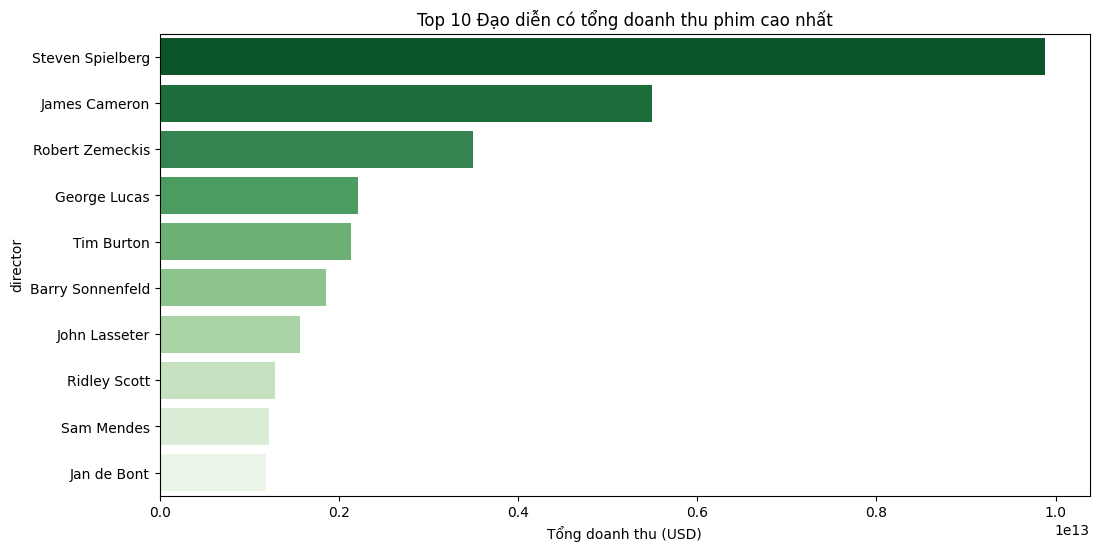

In [124]:
# Gom nhóm theo Đạo diễn và tính tổng doanh thu
# Chỉ lấy những dòng có revenue (tự động bỏ NaN)
director_revenue = full_data.groupby('director')['revenue'].sum().sort_values(ascending=False).head(10)

# Vẽ biểu đồ
plt.figure(figsize=(12, 6))
sns.barplot(x=director_revenue.values, y=director_revenue.index, palette='Greens_r')
plt.title('Top 10 Đạo diễn có tổng doanh thu phim cao nhất')
plt.xlabel('Tổng doanh thu (USD)')
plt.show()

Biểu đồ thanh ngang minh họa Top 10 đạo diễn dẫn đầu về tổng doanh thu phòng vé trong tập dữ liệu, cho thấy sự phân hóa mạnh mẽ về hiệu suất thương mại giữa các nhà làm phim hàng đầu. Nổi bật nhất là sự thống trị tuyệt đối của Steven Spielberg với tổng doanh thu tiệm cận mốc 10 tỷ USD. Cột dữ liệu của ông dài vượt trội, gần gấp đôi so với người đứng thứ hai, khẳng định vị thế "Vua phòng vé" và khả năng tạo ra các tác phẩm đại chúng xuyên suốt nhiều thập kỷ.

Đứng ở vị trí thứ hai là James Cameron với tổng doanh thu đạt khoảng hơn 5.5 tỷ USD. Mặc dù số lượng phim của ông thường ít hơn Spielberg, nhưng hiệu suất doanh thu trên từng đầu phim (như Titanic, Avatar) là cực kỳ lớn giúp ông giữ vững vị trí á quân. Theo sau là Robert Zemeckis ở vị trí thứ ba với khoảng 3.5 tỷ USD, đại diện cho nhóm đạo diễn gạo cội có phong cách làm phim ăn khách bền vững.

Nhóm các đạo diễn còn lại như George Lucas và Tim Burton duy trì mức doanh thu ổn định trong khoảng hơn 2 tỷ USD. Nửa dưới của Top 10 bao gồm Barry Sonnenfeld, John Lasseter, Ridley Scott, Sam Mendes và Jan de Bont với mức doanh thu dao động từ 1.2 đến 1.8 tỷ USD. Nhìn chung, biểu đồ phản ánh rõ quy luật "Winner-takes-all" trong ngành công nghiệp điện ảnh, nơi một nhóm nhỏ các đạo diễn siêu sao (Tier 1) nắm giữ phần lớn thị phần doanh thu so với phần còn lại của thị trường.

#### Phân tích biến mục tiêu Rating 
1. Phân tích đơn biến

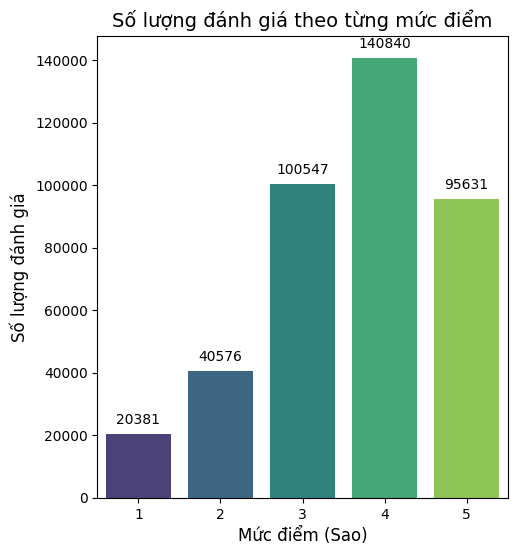

In [125]:
# Thiết lập kích thước tổng thể
plt.figure(figsize=(18, 6))

# --- BIỂU ĐỒ 1: PHÂN PHỐI SỐ LƯỢNG (COUNT PLOT) ---
# Giúp bạn thấy rõ số lượng đánh giá cho từng mức điểm (1-5 sao)
plt.subplot(1, 3, 1)
ax = sns.countplot(x='Rating', data=full_data, palette='viridis')
plt.title('Số lượng đánh giá theo từng mức điểm', fontsize=14)
plt.xlabel('Mức điểm (Sao)', fontsize=12)
plt.ylabel('Số lượng đánh giá', fontsize=12)

# Thêm số liệu cụ thể lên đầu cột để dễ đọc
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center', xytext=(0, 10), textcoords='offset points')

Text(0.5, 1.0, 'Tỷ lệ phần trăm các mức điểm')

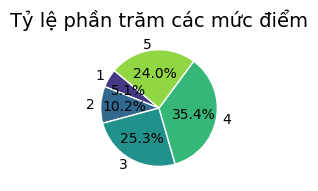

In [126]:
# --- BIỂU ĐỒ 2: TỶ TRỌNG PHẦN TRĂM (PIE CHART) ---
# Giúp hình dung cơ cấu thị hiếu người dùng
plt.subplot(1, 3, 2)
rating_counts = full_data['Rating'].value_counts().sort_index()
plt.pie(rating_counts, labels=rating_counts.index, autopct='%1.1f%%', startangle=140, 
    colors=sns.color_palette('viridis', 5), wedgeprops={'edgecolor': 'white'})
plt.title('Tỷ lệ phần trăm các mức điểm', fontsize=14)

In [127]:
fig = px.histogram(full_data,x='Rating', 
                   labels={'Rating': 'Điểm số', 'count': 'Số lượng'},
                   title="Biểu đồ phân phối điểm số")
fig.update_yaxes(title="Số lượng")
fig.update_traces(
    hovertemplate="Điểm số = %{x}<br>Số lượng = %{y}"
)
fig.show()

Dựa trên biểu đồ phân phối số lượng đánh giá theo từng mức điểm, có thể nhận định rằng dữ liệu mang tính lệch trái rõ rệt, khi phần lớn người dùng tập trung chấm điểm cao. Cụ thể, mức điểm 4 sao xuất hiện nhiều nhất, chiếm hơn 140 nghìn lượt đánh giá, tiếp theo là 5 sao với hơn 95 nghìn lượt. Trong khi đó, các mức điểm thấp (1–2 sao) xuất hiện rất ít. Điều này cho thấy xu hướng đánh giá tích cực là chủ đạo.

Kết quả này phản ánh đúng tâm lý người dùng trong hệ thống đánh giá phim: họ có xu hướng xem những bộ phim phù hợp với sở thích nên thường cho điểm cao. Ngược lại, các bộ phim dở hoặc không phù hợp thường bị bỏ dở, dẫn đến việc người xem không đánh giá hoặc không chấm quá thấp. Vì vậy, điểm 3 sao không thực sự đại diện mức trung bình, mà mang ý nghĩa thiên về mức "trung bình thấp". Một bộ phim muốn được xem là “hay” cần đạt mức 4–5 sao.

In [128]:
# --- IN RA CON SỐ THỐNG KÊ CỤ THỂ ---
mean_rating = full_data['Rating'].mean()
median_rating = full_data['Rating'].median()
print(f"Điểm đánh giá trung bình (Mean): {mean_rating:.2f}")
print(f"Điểm đánh giá trung vị (Median): {median_rating}")

Điểm đánh giá trung bình (Mean): 3.63
Điểm đánh giá trung vị (Median): 4.0


Hai giá trị Mean = 3.63 và Median = 4.0 cho thấy người dùng có xu hướng chấm điểm khá cao cho các bộ phim. Việc trung vị (4.0) lớn hơn trung bình (3.63) chứng tỏ phần lớn đánh giá tập trung ở mức tốt (4–5 sao), trong khi một số ít đánh giá thấp đã kéo trung bình giảm xuống. Trong trường hợp này, Median = 4.0 là giá trị đáng tin cậy hơn để đại diện cho mức độ hài lòng thực tế, vì nó phản ánh điểm điển hình mà phần lớn người dùng chấm, thay vì bị ảnh hưởng bởi một số ít đánh giá cực thấp. Do đó, khi đánh giá chất lượng phim của dataset, mức điểm phổ biến và đáng tin nhất chính là 4 sao.

2. Phân tích đa biến

Trả lời câu hỏi: "Phim càng nhiều người chấm điểm (càng nổi) thì điểm càng cao, hay phim "bom xịt" mới ít người chấm?" thông qua mối tương quan giữa "Độ nổi tiếng" và "Chất lượng"


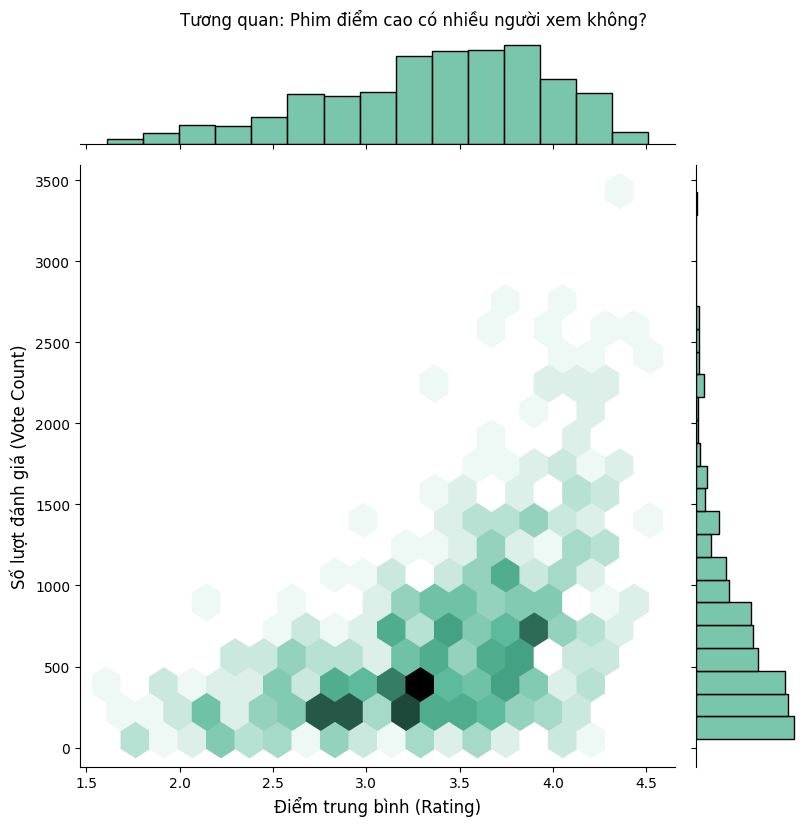

In [129]:
# Biểu đồ Joint Plot: Tương quan giữa "Độ nổi tiếng" và "Chất lượng"
# Tạo một biến đếm số lượng rating cho mỗi phim (Vote Count)
movie_stats = full_data.groupby('Title').agg({'Rating': ['mean', 'count']})
movie_stats.columns = ['avg_rating', 'vote_count']

# Lọc bớt các phim quá ít rating (< 50) để biểu đồ đỡ nhiễu
popular_movies = movie_stats[movie_stats['vote_count'] > 50]

# Vẽ Jointplot kiểu 'hex' (tổ ong) nhìn rất ngầu
# kind='hex' giúp nhìn rõ mật độ tập trung hơn là scatter chấm bi thông thường
g = sns.jointplot(x='avg_rating', y='vote_count', data=popular_movies, 
                  kind='hex', color='#4CB391', height=8)

g.fig.suptitle('Tương quan: Phim điểm cao có nhiều người xem không?', y=1.02)
g.set_axis_labels('Điểm trung bình (Rating)', 'Số lượt đánh giá (Vote Count)', fontsize=12)
plt.show()

Biểu đồ Jointplot (dạng tổ ong) cung cấp một góc nhìn sâu sắc về quy luật đào thải của điện ảnh. Phần lớn các điểm dữ liệu tập trung ở vùng điểm trung bình (3.0 - 3.5) với số lượng đánh giá thấp, phản ánh thực tế rằng đa số các bộ phim đều ở mức thường thường bậc trung và ít được chú ý. Tuy nhiên, khi quan sát các bộ phim có lượng tương tác "khủng" (trên 2000 lượt đánh giá), chúng ta thấy chúng hầu hết đều nằm ở vùng điểm số cao (trên 3.5). Hiện tượng này khẳng định mối tương quan thuận chiều giữa chất lượng và độ nổi tiếng: phim dở thường bị lãng quên nhanh chóng, trong khi chỉ những tác phẩm thực sự chất lượng mới đủ sức tạo ra hiệu ứng đám đông và thu hút lượng người xem lớn.

Trả lời câu hỏi: Đàn ông và Phụ nữ, ai "khắt khe" hơn khi chấm điểm? Boxplot bình thường không cho thấy mật độ, nhưng Violin plot thì có.

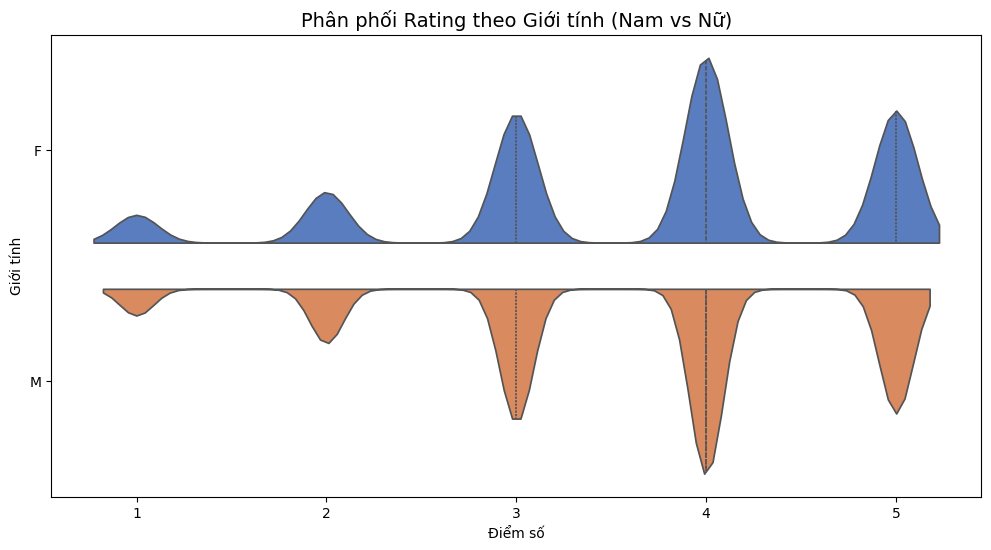

In [130]:
# Biểu đồ Violin Plot: So sánh Rating theo Giới tính/Độ tuổi
full_data = pd.merge(full_data, users[['UserID', 'Gender', 'Age']], on='UserID', how='left')
plt.figure(figsize=(12, 6))

# Vẽ Violin plot
# split=True: Chia đôi cây đàn, một nửa là Nam (M), một nửa là Nữ (F) để dễ so sánh
sns.violinplot(x='Rating', y='Gender', data=full_data, 
               palette='muted', split=True, inner='quartile')

plt.title('Phân phối Rating theo Giới tính (Nam vs Nữ)', fontsize=14)
plt.xlabel('Điểm số')
plt.ylabel('Giới tính')
plt.show()

Về sự khác biệt hành vi giữa các nhóm giới tính Biểu đồ Violin (Violin Plot) cung cấp cái nhìn so sánh thú vị giữa người dùng Nam và Nữ. Mặc dù hình dáng phân phối tổng thể khá tương đồng (đều phình to ở mức 3-4 sao), nhưng có những sự khác biệt tinh tế. Nhóm người dùng Nữ thể hiện sự quyết đoán và hào phóng hơn, biểu hiện qua phần đỉnh nhọn và phình to hơn ở mức 4-5 sao. Trong khi đó, nhóm Nam giới có phổ đánh giá trải rộng hơn một chút xuống các mức điểm thấp (2-3 sao). Tuy nhiên, kết luận chung là giới tính không phải yếu tố gây phân cực sâu sắc về điểm số; cả hai giới đều chia sẻ chung một gu thẩm mỹ "dễ chịu" đối với các bộ phim họ chọn xem.

Trả lời câu hỏi: Thể loại phim nào được ưu ái nhất?

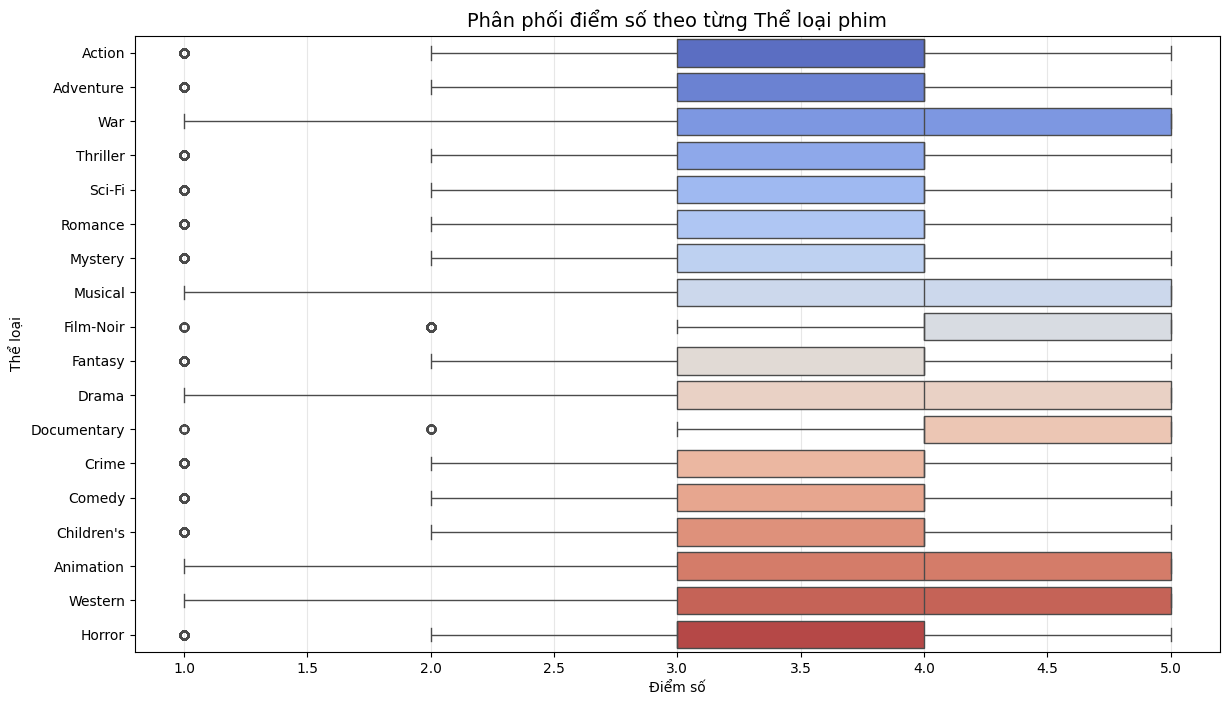

In [131]:
# Biểu đồ Heatmap: Ma trận Thể loại vs. Rating
# 1. Tách thể loại (Explode Genres) - Bước này hơi nặng chút
# Tạo bản sao để không ảnh hưởng dữ liệu gốc
genres_df = full_data[['MovieID', 'Rating', 'Genres']].copy()
# Chuyển chuỗi "Action|Comedy" thành list ["Action", "Comedy"]
genres_df['Genres'] = genres_df['Genres'].str.split('|')
# Bung nén (Explode): Biến 1 dòng chứa list thành nhiều dòng
genres_exploded = genres_df.explode('Genres')

# 2. Vẽ Boxplot sắp xếp theo điểm trung vị
plt.figure(figsize=(14, 8))

# Tính thứ tự sắp xếp: Thể loại nào có điểm trung vị cao nhất xếp trước
order = genres_exploded.groupby('Genres')['Rating'].median().sort_values(ascending=False).index

sns.boxplot(x='Rating', y='Genres', data=genres_exploded, 
            order=order, palette='coolwarm')

plt.title('Phân phối điểm số theo từng Thể loại phim', fontsize=14)
plt.xlabel('Điểm số')
plt.ylabel('Thể loại')
plt.grid(axis='x', alpha=0.3)
plt.show()

Biểu đồ thể hiện sự phân bố điểm đánh giá theo từng thể loại phim và cho thấy sự khác biệt khá rõ về mức độ được yêu thích giữa các dòng phim. Nhìn chung, nhóm thể loại như Documentary, Film-Noir, Drama hay War có điểm trung vị cao nhất, cho thấy những bộ phim thuộc nhóm này thường được đánh giá nghiêm túc và chất lượng nội dung cao, dù có thể không phổ biến về mặt thương mại. Đây là những thể loại thường thu hút nhóm khán giả chuyên sâu và có tiêu chuẩn đánh giá rõ ràng.

Ngược lại, Horror là thể loại có điểm trung vị thấp nhất. Điều này phản ánh tính chất phân cực của phim kinh dị—đa số khán giả dễ thất vọng nếu nội dung không đủ mới mẻ, hoặc phim thiên về giải trí hù dọa thay vì cốt truyện sâu. Các thể loại phổ biến như Action, Adventure hay Sci-Fi có mức điểm trung bình khá ổn định quanh vùng 3.3–3.8, thể hiện tính đại chúng và phù hợp thị hiếu rộng hơn.

Đáng chú ý, hầu hết các thể loại đều có vài giá trị ngoại lai (outliers), chứng tỏ mỗi nhóm vẫn tồn tại cả phim rất kém và phim xuất sắc, tạo nên độ chênh nhất định trong phân phối điểm. Tổng thể, biểu đồ cho thấy sự phân hóa thú vị giữa các thể loại: những nhóm có ít người xem lại thường được đánh giá cao, trong khi các thể loại đại chúng ghi nhận mức điểm vừa phải hơn nhưng ổn định hơn.

Đang phân tích tương quan trên 617 bộ phim với các biến:
['release_year', 'budget', 'revenue', 'vote_average', 'vote_count', 'avg_rating', 'runtime', 'Age']


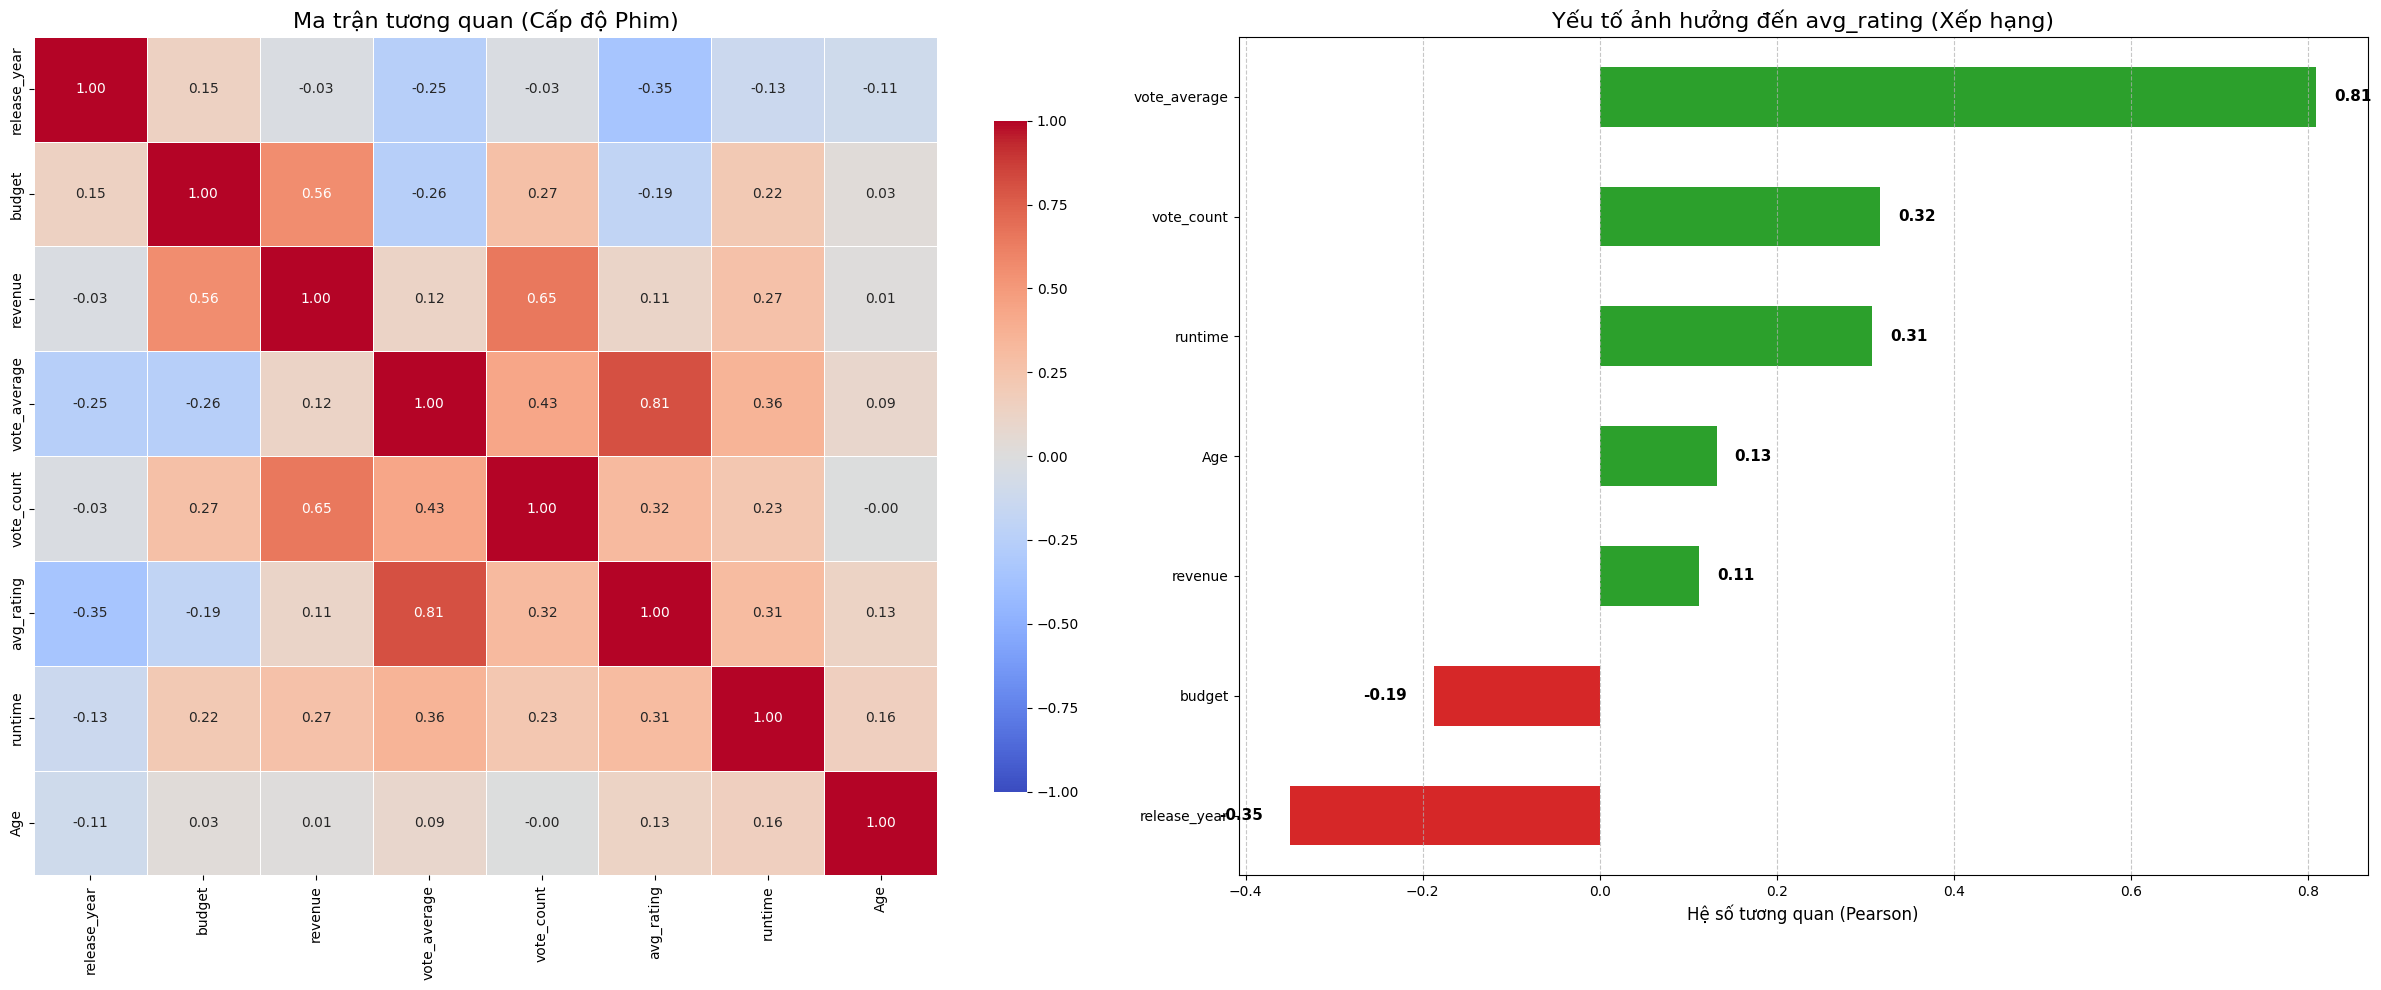

In [132]:
# --- BƯỚC 1: CHUẨN BỊ DỮ LIỆU CẤP ĐỘ PHIM (QUAN TRỌNG) ---
# Chỉ giữ lại mỗi phim 1 dòng để tính toán các chỉ số vĩ mô (Budget, Revenue...)
df_movie_scope = full_data.drop_duplicates(subset=['MovieID']).copy()

# --- BƯỚC 2: TỰ ĐỘNG CHỌN CỘT SỐ ---

# 1. Lấy tất cả cột số
all_numeric_cols = df_movie_scope.select_dtypes(include=[np.number]).columns.tolist()

# 2. Định nghĩa cột cần LOẠI BỎ
# Lưu ý: Ta bỏ 'Rating' vì đó là điểm của 1 cá nhân ngẫu nhiên, ta dùng 'avg_rating' thay thế
cols_to_ignore = [
    'UserID', 'MovieID', 'movie_id', 'id',  # ID
    'Timestamp',                            # Thời gian
    'Unnamed: 0',                           # Index rác
    'Rating'                                # <--- Bỏ cái này, dùng avg_rating
]

# 3. Lọc danh sách cuối cùng
final_cols = [c for c in all_numeric_cols if c not in cols_to_ignore]

print(f"Đang phân tích tương quan trên {df_movie_scope.shape[0]} bộ phim với các biến:")
print(final_cols)

# 4. Tính ma trận tương quan
corr_matrix = df_movie_scope[final_cols].corr()

# --- BƯỚC 3: VẼ BIỂU ĐỒ ---

fig_height = 10 if len(final_cols) < 15 else 15 
fig, ax = plt.subplots(1, 2, figsize=(24, fig_height))

# 3.1. Vẽ Heatmap (Bên trái)
sns.heatmap(corr_matrix, 
            annot=True, 
            fmt=".2f", 
            cmap='coolwarm', 
            vmin=-1, vmax=1, 
            linewidths=0.5, 
            ax=ax[0],
            cbar_kws={"shrink": .8})
ax[0].set_title('Ma trận tương quan (Cấp độ Phim)', fontsize=16)

# 3.2. Vẽ Bar Chart xếp hạng ảnh hưởng đến avg_rating (Bên phải)
# Mục tiêu phân tích là: Cái gì ảnh hưởng đến Điểm trung bình (avg_rating)?
target_col = 'avg_rating'

if target_col in corr_matrix.columns:
    target_corr = corr_matrix[target_col].drop(target_col).sort_values(ascending=True)

    # Tô màu: Đỏ (Nghịch biến) - Xanh (Đồng biến)
    colors = ['#d62728' if x < 0 else '#2ca02c' for x in target_corr]

    target_corr.plot(kind='barh', color=colors, ax=ax[1])

    # Trang trí
    ax[1].set_title(f'Yếu tố ảnh hưởng đến {target_col} (Xếp hạng)', fontsize=16)
    ax[1].set_xlabel('Hệ số tương quan (Pearson)', fontsize=12)
    ax[1].grid(axis='x', linestyle='--', alpha=0.7)

    # Thêm nhãn số liệu
    for index, value in enumerate(target_corr):
        offset = 0.02 if value >= 0 else -0.08 # Chỉnh offset để số không đè lên cột
        ax[1].text(value + offset, index, f'{value:.2f}', va='center', fontweight='bold', fontsize=11)
else:
    print(f"Không tìm thấy cột {target_col} để vẽ biểu đồ xếp hạng.")

plt.tight_layout()
plt.show()

Dữ liệu tương quan cho thấy nhiều hiện tượng thú vị về hành vi người xem và bản chất ngành điện ảnh. Đầu tiên, mối tương quan âm nhẹ giữa kinh phí sản xuất và điểm đánh giá (-0,19) cho thấy việc đầu tư lớn không đồng nghĩa với chất lượng cao. Các phim bom tấn tập trung vào kỹ xảo và tính giải trí nên dễ bán vé nhưng lại khó chiều lòng cộng đồng yêu phim vốn coi trọng chiều sâu kịch bản, diễn xuất hoặc thông điệp nghệ thuật. Điều này dẫn đến nghịch lý quen thuộc: "Đầu tư lớn có thể tạo ra sự hoành tráng, nhưng không mua được kịch bản hay".

Ngược lại, sự tương quan cực mạnh (+0,81) giữa điểm trung bình của TMDB và MovieLens thể hiện sự đồng nhất về thị hiếu người xem trên quy mô toàn cầu. Đây là tín hiệu rất tốt về độ tin cậy của dữ liệu, đồng thời cho thấy việc ghép dữ liệu là hoàn toàn hợp lý. Một bộ phim hay thì dù được đánh giá ở cộng đồng Mỹ hay quốc tế đều nhận được sự đánh giá tích cực.

Một hiện tượng ngược dòng đáng chú ý xuất hiện ở biến thời gian phát hành. Phim ra mắt càng muộn thì điểm đánh giá lại có xu hướng thấp hơn (tương quan -0,35). Tuy nhiên, điều này không có nghĩa phim hiện đại kém chất lượng hơn. Đây là trường hợp điển hình của "hiệu ứng kẻ sống sót": chỉ những tác phẩm xuất sắc của thời kỳ trước mới được lưu giữ và đánh giá cho tới ngày nay, trong khi các tác phẩm tầm thường đã biến mất khỏi hệ thống, khiến các giá trị trung bình của phim cũ cao hơn.

Mặt khác, kết quả xác nhận quy luật kinh tế quen thuộc: “rủi ro cao, lợi nhuận cao”. Mối liên hệ giữa ngân sách và doanh thu ở mức mạnh (+0,65), phản ánh hiệu quả đầu tư của các hãng phim. Các tác phẩm kinh phí lớn đi kèm chiến dịch quảng bá mạnh mẽ, số lượng suất chiếu rộng rãi và độ phủ truyền thông lớn, từ đó mang về doanh thu cao.

Cuối cùng, chất lượng và doanh thu có liên hệ nhưng không mạnh (tương quan +0,11). Điều này có thể hiểu rằng phim hay thường có doanh thu tốt hơn, nhưng chưa đủ mạnh để đưa ra kết luận ngược lại. Những phim nghệ thuật chất lượng cao thường kén khán giả, doanh thu thấp; còn phim giải trí chỉ cần hiệu ứng truyền thông cũng có thể mang về doanh thu lớn. Điều này cho thấy doanh thu phụ thuộc nhiều hơn vào chiến lược marketing và sức hút thương hiệu, thay vì nội dung thuần túy.

## Phân tích Chuyên sâu - Các yếu tố ảnh hưởng Rating

1. Yếu tố Tài chính: Ngân sách (Budget) hoặc Doanh thu (Revenue) có mối liên hệ tích cực hay tiêu cực đối với rating trung bình của phim?

2. Yếu tố Nội dung & Cấu trúc: Các Thể loại (Genre) phim khác nhau có xu hướng nhận được mức rating trung bình khác nhau đáng kể không? Độ dài phim (Movie length) có ảnh hưởng đến việc người dùng đánh giá cao hay thấp?

3. Yếu tố Nhân sự & Thời gian: Vai trò của Đạo diễn/diễn viên có tên tuổi lớn có tương quan mạnh mẽ với rating người dùng cao hơn không? Năm sản xuất (phim cũ/mới) có ảnh hưởng đến rating trung bình không?

### Các công thức sử dụng để đánh giá các mô hình:

1. Precision (Độ chính xác)Đây là thước đo sự "Tin cậy". Nó trả lời câu hỏi: "Khi mô hình cảnh báo một sự kiện, xác suất nó đúng là bao nhiêu?"Công thức:$$\text{Precision} = \frac{\text{TP}}{\text{TP} + \text{FP}}$$

2. Recall (Độ nhạy / Tỷ lệ phát hiện)Đây là thước đo sự "Bao phủ". Nó trả lời câu hỏi: "Mô hình tìm ra được bao nhiêu % sự kiện thực tế trong tổng số sự kiện đang có?"Công thức:$$\text{Recall} = \frac{\text{TP}}{\text{TP} + \text{FN}}$$

3. F1-Score (Điểm cân bằng)Đây là chỉ số tổng hợp, là trung bình điều hòa của Precision và Recall. Nó dùng để đánh giá khi bạn cần cân bằng giữa việc "Đoán chuẩn" và "Không bỏ sót".Công thức:$$\text{F1-Score} = 2 \times \frac{\text{Precision} \times \text{Recall}}{\text{Precision} + \text{Recall}}$$

trong đó:

+ TP (True Positive): Số lượng dự báo đúng cho lớp đó (Ví dụ: Máy báo "Sa sút" và đúng là "Sa sút").

+ FP (False Positive): Số lượng báo động giả (Ví dụ: Máy báo "Sa sút" nhưng thực tế là "Bình thường").

+ FN (False Negative): Số lượng bỏ sót (Ví dụ: Thực tế là "Sa sút" nhưng máy báo là "Bình thường").

+ TN (True Negative): Số lượng dự báo đúng là không phải lớp đó.

4. Support (Số lượng mẫu)
Đây không phải là chỉ số hiệu suất, mà là số lượng mẫu thực tế trong tập kiểm tra (Test set).

5. Các chỉ số Tổng hợp (Averages)Accuracy (Độ chính xác toàn cục):$$\text{Accuracy} = \frac{\text{Tổng số dự đoán đúng}}{\text{Tổng số mẫu}}$$

+ Macro Avg: Trung bình cộng của Precision/Recall các lớp mà không quan tâm số lượng mẫu. (Dùng để đánh giá công bằng cho các lớp thiểu số).

+ Weighted Avg: Trung bình cộng có trọng số dựa trên số lượng mẫu (Support). (Chỉ số này thường cao vì nó bị chi phối bởi lớp đa số "Bình thường").



### 1. Yếu tố Tài chính
Ngân sách (Budget) hoặc Doanh thu (Revenue) có mối liên hệ tích cực hay tiêu cực đối với rating trung bình của phim?

#### c. Phân tích tương quan

Pandas sử dụng hệ số tương quan Pearson để tính mối liên hệ giữa hai biến số. Công thức tổng quát như sau:
$$
r_{XY} = 
\frac{\displaystyle \sum_{i=1}^{n} (X_i - \bar{X})(Y_i - \bar{Y})}
{\sqrt{\displaystyle \sum_{i=1}^{n} (X_i - \bar{X})^2 } \;
 \sqrt{\displaystyle \sum_{i=1}^{n} (Y_i - \bar{Y})^2 }}
$$

##### Ý nghĩa

**Tử số:**

$$
\sum_{i=1}^{n} (X_i - \bar{X})(Y_i - \bar{Y})
$$

Đo mức độ mà X và Y cùng tăng hoặc cùng giảm:

- Nếu X tăng → Y cũng tăng → tích số dương  
- Nếu X tăng → Y giảm → tích số âm  

**Mẫu số:**

$$
\sqrt{\sum_{i=1}^{n} (X_i - \bar{X})^2 } \cdot 
\sqrt{\sum_{i=1}^{n} (Y_i - \bar{Y})^2 }
$$

Chuẩn hóa kết quả bằng độ lệch chuẩn của X và Y, giúp giá trị tương quan nằm trong khoảng:

$$
-1 \le r \le 1
$$


##### Diễn giải giá trị tương quan

r≈1: mối quan hệ tuyến tính mạnh, cùng chiều

r≈−1: mối quan hệ tuyến tính mạnh, ngược chiều

r≈0: hầu như không có mối quan hệ tuyến tính

##### Ý nghĩa trong phân tích phim

corr_budget cho biết ngân sách có liên quan như thế nào đến rating.

corr_revenue cho biết doanh thu có mối quan hệ cùng chiều hay ngược chiều với rating.

#### d. Trực quan hóa

Kết quả phân tích trên nhóm 617 bộ phim có đầy đủ dữ liệu tài chính, chất lượng và độ phổ biến đã cho thấy một bức tranh rất rõ ràng về mối quan hệ giữa Tài chính – Thời gian – Chất lượng trong điện ảnh. Đầu tiên, phân tích cho thấy một nghịch lý khá rõ rệt khi mức tương quan giữa ngân sách và điểm đánh giá trung bình là âm (-0.19). Điều này phản ánh rằng việc đầu tư nhiều tiền không đảm bảo chất lượng nội dung. Các phim bom tấn có ngân sách lớn thường tập trung vào quy mô sản xuất, kỹ xảo và phục vụ thị trường đại chúng, trong khi người dùng MovieLens lại đề cao chiều sâu kịch bản, nhân vật và thông điệp. Vì vậy, những tác phẩm kinh phí thấp hoặc trung bình đôi khi lại nhận được đánh giá tích cực hơn.

Ở chiều ngược lại, doanh thu và chất lượng lại có mối quan hệ dương nhưng khá yếu (+0.11). Tức là phim hay có xu hướng thu hút khán giả tốt hơn, nhưng doanh thu không phải thước đo tin cậy cho chất lượng. Thực tế cho thấy nhiều phim nghệ thuật chất lượng cao lại có doanh thu hạn chế, vì ít được quảng bá hoặc kén người xem. Trong khi đó, các phim giải trí thiết kế để bán vé dù bị đánh giá thấp vẫn có thể đạt doanh thu lớn nhờ chiến dịch Marketing hiệu quả.

Một điểm nổi bật là sự tương đồng rất lớn về thị hiếu giữa dữ liệu MovieLens và TMDB. Tương quan +0.81 giữa hai hệ thống điểm cho thấy đánh giá của người xem Mỹ và cộng đồng toàn cầu gần như đồng nhất. Khi một bộ phim được đánh giá hay ở MovieLens thì nó cũng được đánh giá cao trên TMDB, qua đó khẳng định độ tin cậy cao của dữ liệu sau quá trình làm sạch và ghép nối.

Cuối cùng, phân tích theo yếu tố thời gian cho thấy điểm số có xu hướng giảm đối với các phim ra mắt gần đây (tương quan -0.35). Tuy nhiên, nguyên nhân chính nằm ở hiệu ứng "Thiên kiến kẻ sống sót". Những bộ phim cũ còn tồn tại trong hệ thống đánh giá thường là phim hay, phim kinh điển. Các tác phẩm yếu kém của thời kỳ đó đã gần như biến mất khỏi dữ liệu. Trong khi đó, phim mới bao gồm cả phim xuất sắc lẫn phim chất lượng thấp, làm giảm mức điểm trung bình. Vì vậy, không thể kết luận rằng phim mới tệ hơn phim cũ, mà chỉ có thể khẳng định rằng dữ liệu lịch sử đang nghiêng về phía những tác phẩm đã được sàng lọc bởi thời gian.

Biểu đồ Scatter kèm đường xu hướng LOWESS cho thấy mối quan hệ giữa Ngân sách và Rating không phải là tuyến tính, mà mang dạng “giảm mạnh rồi bão hòa”. Ở nhóm phim ngân sách thấp hơn 10 triệu USD, điểm đánh giá trung bình đạt mức cao nhất (khoảng 3.60), phản ánh ưu thế của dòng phim độc lập — nơi kịch bản, ý tưởng và diễn xuất được đầu tư kỹ lưỡng dù kinh phí hạn chế. Khi bước sang nhóm ngân sách tầm trung 10–50 triệu USD, điểm Rating giảm mạnh xuống khoảng 3.30. Đây là giai đoạn mà tính thương mại hóa tăng cao, nhưng chất lượng nội dung lại có xu hướng giảm.

Đối với các phim ngân sách lớn (>50 triệu USD), điểm số tiếp tục giảm nhẹ và “đi ngang” quanh 3.22–3.25. Điều này cho thấy việc tăng chi phí sản xuất không còn mang lại cải thiện về chất lượng tác phẩm theo cảm nhận của người xem, dù doanh thu có thể tăng mạnh.

#### e. Phân tích các yếu tố quốc gia sản xuất ảnh hưởng đến rating phim

Dữ liệu từ biểu đồ cho thấy một bức tranh thú vị về mối tương quan giữa số lượng tác phẩm và chất lượng đánh giá trung bình. Nổi bật nhất là Vương quốc Anh, quốc gia đang dẫn đầu bảng xếp hạng. Với 74 bộ phim góp mặt, điện ảnh Anh không chỉ đảm bảo độ phủ nhất định mà còn khẳng định vị thế "bảo chứng chất lượng" của mình. Điều này có thể lý giải bởi phong cách làm phim thiên về chính kịch, lịch sử và chiều sâu kịch bản vốn là thế mạnh của xứ sở sương mù, rất phù hợp với gu thưởng thức của cộng đồng MovieLens.

Ở một thái cực khác, Hoa Kỳ mang đến góc nhìn điển hình về bài toán quy mô. Mặc dù sở hữu số lượng phim áp đảo hoàn toàn với 586 tác phẩm, điểm trung bình của Mỹ lại xếp sau Anh và chỉ ngang bằng Úc. Điều này phản ánh thực tế rằng khi sản lượng quá lớn, chất lượng sẽ bị pha loãng bởi sự lẫn lộn giữa các siêu phẩm xuất sắc và những bộ phim thương mại đại trà hoặc kém chất lượng. Trong khi đó, Úc là một biến số thú vị khi chen chân vào top đầu với điểm số rất cao, tuy nhiên dữ liệu của quốc gia này (10 phim) là con số tối thiểu để lọt vào danh sách, nên có thể xem đây là những tác phẩm chọn lọc kỹ lưỡng ("quý hồ tinh, bất quý hồ đa").

#### Kết luận

Yếu tố quốc gia có ảnh hưởng rõ rệt đến Rating, nhưng không tuân theo quy luật "nước lớn thì điểm cao". Các quốc gia như Pháp, Đức hay Canada dù xếp sau nhưng vẫn duy trì mức điểm khá ổn định (trên 3.0). Kết quả này gợi ý rằng các nền điện ảnh có tính chọn lọc cao hoặc tập trung vào dòng phim nghệ thuật (như Anh và Châu Âu) thường dễ dàng chinh phục được những khán giả khó tính hơn so với nền công nghiệp điện ảnh tập trung vào số lượng khổng lồ.

#### f. Phân cụm, phân nhóm

#### g. Hồi quy tiêu chuẩn

##### Phân tích Hệ số (Coefficient Analysis) - Yếu tố nào thực sự quan trọng?

Những yếu tố "Quyền lực" nhất (Hệ số lớn):

 + Popularity (+0.18): Tác động dương mạnh nhất. Một lần nữa khẳng định độ phổ biến là chỉ báo tốt nhất cho chất lượng.

 + Horror (-0.12) & Children's (-0.08): Tác động âm. Các phim Kinh dị và Trẻ em thường bị trừ điểm nặng nề trong mắt cộng đồng MovieLens.

 + Year (-0.12): Tác động âm. Phim càng mới (năm phát hành càng lớn), điểm càng có xu hướng thấp đi (xác nhận lại phân tích về "thiên kiến thời gian").

 + Budget (-0.10): Tác động âm. Lasso xác nhận rằng sau khi cân nhắc mọi yếu tố, việc chi quá nhiều tiền (Ngân sách cao) thực sự có tác động tiêu cực đến điểm số.

 + Animation (+0.10): Tác động dương. Phim Hoạt hình thường được đánh giá cao hơn mặt bằng chung.

##### Những "insight" đắt giá nhất mà dữ liệu đã kể cho chúng ta:

1. "Nghịch lý" Tài chính: Tiền không mua được Chất lượng

Đây là phát hiện thú vị của nghiên cứu.

 + Ngân sách (Budget): Có mối tương quan âm (-) hoặc phi tuyến tính với Rating. Việc đổ hàng trăm triệu USD vào kỹ xảo (Blockbuster) thường dẫn đến điểm số đi ngang hoặc giảm nhẹ (~3.2).

 + Điểm sáng Indie: Các bộ phim có kinh phí thấp lại là nhóm có điểm đánh giá trung bình cao nhất (~3.57).

-> Kết luận: Khán giả trên MovieLens ưu tiên chiều sâu kịch bản (thứ ít tốn tiền) hơn là sự hoành tráng về hình ảnh (thứ tốn rất nhiều tiền).

2. Các Yếu tố "Quyền lực" nhất (Key Drivers)

 + Độ phổ biến (Popularity): Là chỉ báo số 1. Một bộ phim được cộng đồng quan tâm, bàn tán nhiều (dù tích cực hay tiêu cực) thường có xu hướng nhận được điểm đánh giá cao hơn.

 + Thời lượng (Runtime): Tác động dương. Phim dài thường được đánh giá là nghiêm túc, có đầu tư về nội dung (Drama, Epic) và được cộng đồng ưu ái hơn phim ngắn giải trí đơn thuần.

 + Năm phát hành (Year): Tác động âm. Phim càng mới, điểm càng có xu hướng khắt khe hơn. Phim cũ được hưởng lợi từ "thiên kiến sinh tồn" (chỉ phim hay mới được nhớ đến).

3. Yếu tố Nội dung & Xuất xứ

Thể loại (Genre):

 + Nên tránh: Phim Kinh dị (Horror) và Trẻ em (Children's) thường bị trừ điểm nặng nề trong các mô hình dự báo.

 + Nên làm: Phim Hoạt hình (Animation), Tài liệu (Documentary) và Phim Noir là những "mỏ vàng" về điểm số.

Quốc gia: Chất lượng phim từ Vương quốc Anh (UK) vượt trội hơn so với Mỹ (USA) về mặt điểm số trung bình, cho thấy sự thắng thế của phong cách làm phim thiên về nghệ thuật/kịch bản so với phong cách thương mại hóa.

##### "Công thức" cho một bộ phim Rating cao

Nếu dữ liệu phải đưa ra lời khuyên cho một nhà sản xuất phim muốn đạt điểm Rating cao trên MovieLens, công thức sẽ là:

"Hãy làm một bộ phim Tâm lý (Drama) hoặc Hoạt hình, có thời lượng dài (trên 2 tiếng), chú trọng vào kịch bản thay vì kỹ xảo đắt tiền (ngân sách vừa phải), có thể hợp tác sản xuất với Anh Quốc, và quan trọng nhất là phải tạo được hiệu ứng truyền thông (Popularity) mạnh mẽ trước khi ra mắt."

### 2. Yếu tố Nội dung & Cấu trúc
Các Thể loại (Genre) phim khác nhau có xu hướng nhận được mức rating trung bình khác nhau đáng kể không? Độ dài phim (Movie length) có ảnh hưởng đến việc người dùng đánh giá cao hay thấp?

### 3. Yếu tố Nhân sự & Thời gian
Vai trò của Đạo diễn/diễn viên có tên tuổi lớn có tương quan mạnh mẽ với rating người dùng cao hơn không? Năm sản xuất (phim cũ/mới) có ảnh hưởng đến rating trung bình không?

- Input: director_power, actor_power, release_year.
- Output: cột Rating thực tế.

**1**. Dữ liệu: Sử dụng kỹ thuật Target Encoding để chuyển đổi dữ liệu định danh (tên người) thành dữ liệu định lượng (điểm số lịch sử), đại diện cho "Sức hút thương hiệu" (Star Power).

**2**. Mô hình: Sử dụng XGBoost Regressor, một mô hình phi tuyến tính mạnh mẽ để nắm bắt các mối quan hệ phức tạp giữa nhân sự, thời gian và chất lượng phim.

**3**. Phân tích: Áp dụng phương pháp SHAP (Shapley Additive exPlanations) để bóc tách mức độ đóng góp của từng yếu tố, giúp trả lời câu hỏi liệu "Tên tuổi lớn" có thực sự là nguyên nhân trực tiếp dẫn đến "Rating cao" hay không.

XGBoost là lựa chọn vượt trội vì nó mô hình hóa được tính phi tuyến và tương tác phức tạp giữa các yếu tố mà hồi quy tuyến tính không làm được. Thực tế dữ liệu phim không đi theo dạng đường thẳng: ngân sách thấp → điểm tăng, ngân sách rất cao → điểm lại giảm; hoặc từng giai đoạn sản xuất phim có chất lượng khác nhau. Với nhiều cây quyết định, XGBoost có thể chia dữ liệu thành từng vùng và học được chính xác quy luật này.

Ngoài ra, XGBoost tự động phát hiện các tương tác quan trọng, ví dụ một thể loại phim ở một thời kỳ nhất định sẽ có điểm cao hơn. Khi kết hợp với SHAP, mô hình còn giải thích rõ mức đóng góp của từng yếu tố như đạo diễn, diễn viên hay thời điểm phát hành.

#### 1. Số hóa sức mạnh nhân sự (Feature Engineering)

Công thức:$$P_D = \frac{\sum_{i=1}^{n} r_i}{n}$$Chú thích:

>$P_D$: Chỉ số sức mạnh (Power) của Đạo diễn/Diễn viên $D$ (Giá trị sau khi mã hóa).

>$r_i$: Điểm Rating thực tế của bộ phim thứ $i$ mà người đó tham gia.

>$n$: Tổng số lượng phim mà người đó đã tham gia trong tập dữ liệu huấn luyện.

In [134]:
# Ý tưởng: "Tên tuổi lớn" = Người có lịch sử làm phim điểm cao.
# Ta sẽ tính điểm trung bình của từng Đạo diễn/Diễn viên và gán lại cho họ.

# 1. Tạo biến "Sức mạnh Đạo diễn" (Director Power)
# Dùng transform để gán ngược lại vào từng dòng dữ liệu
full_data['director_power'] = full_data.groupby('director')['Rating'].transform('mean')

# 2. Tạo biến "Sức mạnh Diễn viên" (Actor Power)
full_data['actor_power'] = full_data.groupby('actor_1')['Rating'].transform('mean')

# # 3. Chuẩn bị dữ liệu cho mô hình
# # Chỉ lấy 3 cột bạn quan tâm: Đạo diễn, Diễn viên, Năm sản xuất
features = ['director_power', 'actor_power', 'release_year']
X = full_data[features]
y = full_data['Rating']

#### 2. Huấn luyện XGBoost Regressor

XGBoost Regressor là một mô hình phi tuyến tính mạnh mẽ để nắm bắt các mối quan hệ phức tạp giữa nhân sự, thời gian và chất lượng phim.

a. Công thức Dự đoán (Additive Prediction): Dự đoán cuối cùng là tổng hợp kết quả của $K$ cây quyết định (Decision Trees).$$\hat{y}_i = \sum_{k=1}^{K} f_k(x_i), \quad f_k \in \mathcal{F}$$

Chú thích:

>$\hat{y}_i$: Điểm Rating dự đoán cho bộ phim $i$.

>$K$: Tổng số lượng cây quyết định (trong code là n_estimators).

>$f_k(x_i)$: Điểm số dự đoán của cây thứ $k$ dựa trên đặc trưng đầu vào $x_i$ (Budget, Director Power, Year...).

>$\mathcal{F}$: Không gian chứa tất cả các cây quyết định có thể.

b. Hàm Mục tiêu (Objective Function): XGBoost tối ưu hóa hàm này để giảm sai số và tránh Overfitting.$$\mathcal{L}(\phi) = \sum_{i} l(y_i, \hat{y}_i) + \sum_{k} \Omega(f_k)$$

Chú thích:

>$l(y_i, \hat{y}_i)$: Hàm mất mát (Loss function), thường là Sai số bình phương (MSE) để đo sự chênh lệch giữa Rating thực tế và dự đoán.

>$\Omega(f_k)$: Số hạng điều chuẩn (Regularization term). Nó phạt các cây quá phức tạp để mô hình không bị học vẹt (Overfitting).

In [135]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Đang huấn luyện mô hình...")
model = xgb.XGBRegressor(
    n_estimators=1000,   # Tăng số cây lên (vì ta sẽ dừng sớm nếu nó học xong)
    learning_rate=0.05,  # Học chậm lại chút cho chắc
    max_depth=4, 
    random_state=42,
    n_jobs=-1,
    early_stopping_rounds=50 # QUAN TRỌNG: Nếu sau 50 cây mà không khôn hơn thì dừng lại (Chống học vẹt)
)

# Đưa cả tập Test vào để mô hình tự kiểm tra (eval_set)
model.fit(
    X_train, y_train, 
    eval_set=[(X_test, y_test)], 
    verbose=False
)

# Kiểm tra sai số
preds = model.predict(X_test)
rmse = np.sqrt(mean_squared_error(y_test, preds))
print(f"Sai số trung bình (RMSE) trên tập Test: {rmse:.4f}")
# Nếu RMSE ~ 0.8 - 1.0 là ổn (vì thang điểm 5, lệch 1 sao là chấp nhận được)

Đang huấn luyện mô hình...
Sai số trung bình (RMSE) trên tập Test: 0.9839


early_stopping_rounds=50: Đây là kỹ thuật chống Overfitting mạnh nhất của XGBoost. Nó sẽ quan sát tập X_test. Nếu nó thấy học thêm mà kết quả trên tập Test không tốt lên (bắt đầu học vẹt), nó sẽ tự động dừng lại ngay lập tức, dù chưa chạy hết 1000 cây.

Tính RMSE: Cho bạn một con số để báo cáo độ tin cậy. Ví dụ: "Mô hình dự đoán sai lệch trung bình khoảng 0.9 sao".

#### 3. Phân tích SHAP

SHAP (SHapley Additive exPlanations) là một kỹ thuật xuất phát từ Lý thuyết Trò chơi (Game Theory), dùng để giải thích các mô hình "hộp đen" phức tạp như XGBoost.

SHAP có nhiệm vụ chia nhỏ kết quả dự đoán (Rating) thành các phần đóng góp công bằng của từng yếu tố (Đạo diễn, Diễn viên, Tiền...), giúp chúng ta hiểu được mô hình đang "nghĩ" gì.

Giá trị SHAP ($\phi_j$) của một đặc trưng $j$ (ví dụ: director_power) được tính bằng:$$\phi_j(val) = \sum_{S \subseteq \{x_1,...,x_p\} \setminus \{x_j\}} \frac{|S|! (p - |S| - 1)!}{p!} (val(S \cup \{x_j\}) - val(S))$$

Ý nghĩa:
>$val(S)$: Điểm dự đoán của mô hình khi chưa có thông tin về Đạo diễn.

>$val(S \cup \{x_j\})$: Điểm dự đoán của mô hình khi đã thêm thông tin về Đạo diễn vào.

>$(val(S \cup \{x_j\}) - val(S))$: Gọi là Đóng góp biên (Marginal Contribution). Tức là sự chênh lệch điểm số do chính ông Đạo diễn này tạo ra.

>Phần còn lại: Là trọng số trung bình tính trên tất cả các trường hợp tổ hợp có thể xảy ra.

In [136]:
# Tính giá trị SHAP để xem mức độ tác động
explainer = shap.Explainer(model)
shap_values = explainer(X)

#### 4. Vẽ biểu đồ (SHAP Dependence Plots)

Trục Hoành (X-axis): Giá trị thực tế của dữ liệu (Ví dụ: Điểm lịch sử của Đạo diễn là 3.0 hay 4.0).

Trục Tung (Y-axis - SHAP value): Mức độ tác động lên điểm Rating dự đoán.

+ Giá trị > 0: Yếu tố này giúp Cộng điểm cho phim (Kéo Rating lên).

+ Giá trị < 0: Yếu tố này làm Trừ điểm phim (Kéo Rating xuống).

+ Giá trị = 0: Không ảnh hưởng.

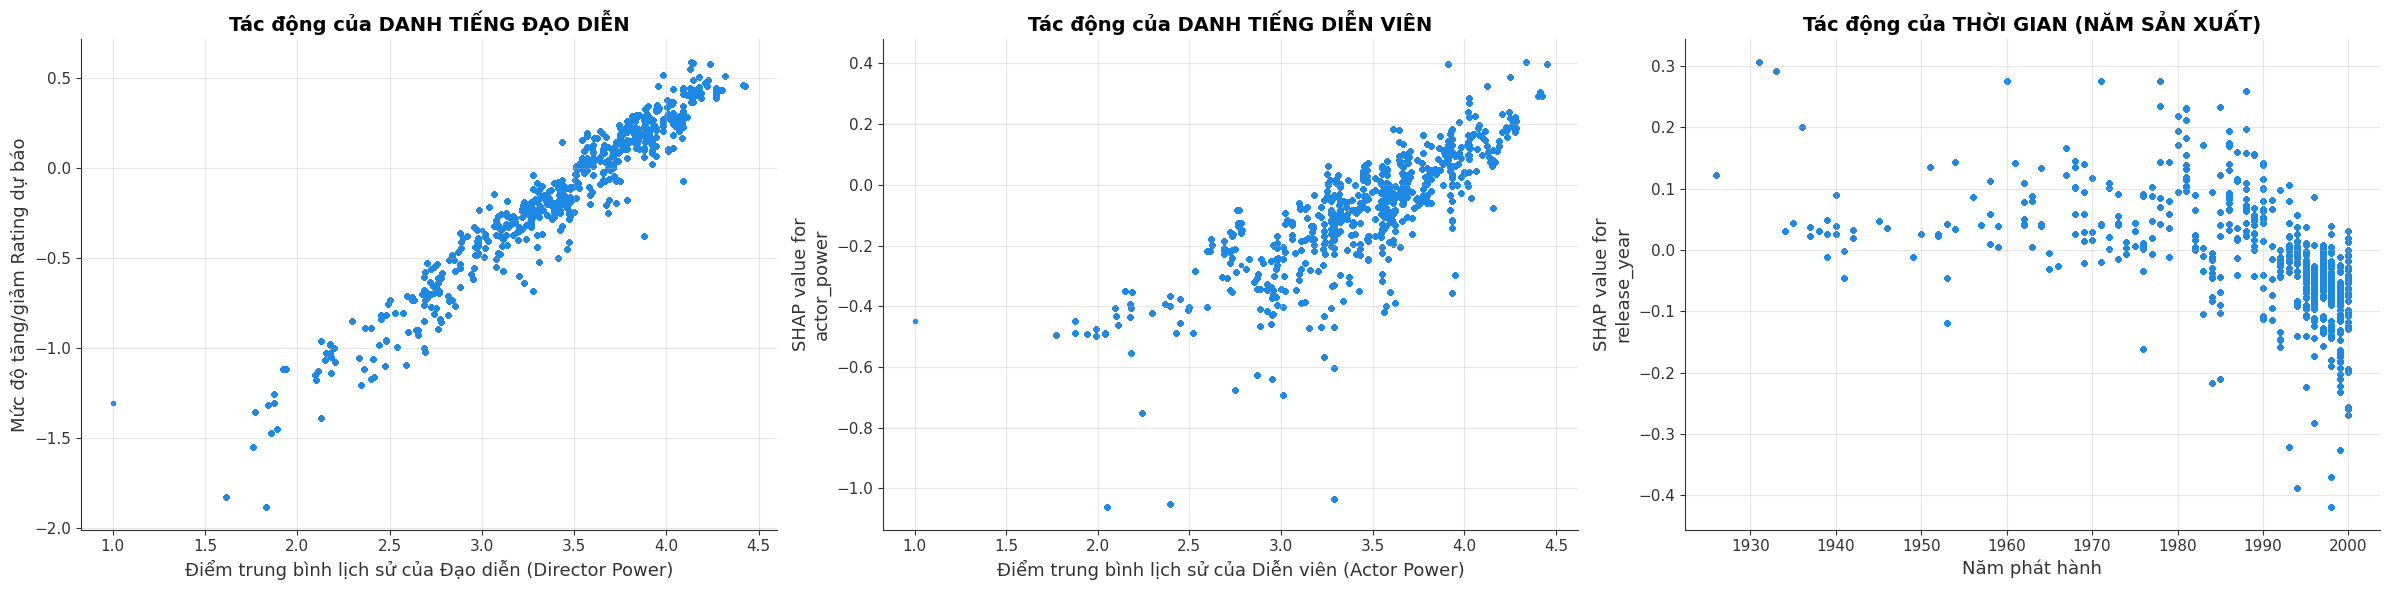

In [138]:
fig, ax = plt.subplots(1, 3, figsize=(24, 6))

# Câu hỏi 1: ĐẠO DIỄN có tên tuổi lớn (Rating lịch sử cao) có kéo điểm phim lên không?
shap.dependence_plot("director_power", shap_values.values, X, interaction_index=None, ax=ax[0], show=False)
ax[0].set_title("Tác động của DANH TIẾNG ĐẠO DIỄN", fontsize=14, fontweight='bold')
ax[0].set_xlabel("Điểm trung bình lịch sử của Đạo diễn (Director Power)")
ax[0].set_ylabel("Mức độ tăng/giảm Rating dự báo")
ax[0].grid(True, alpha=0.3)

# Câu hỏi 2: DIỄN VIÊN có tên tuổi lớn có kéo điểm phim lên không?
shap.dependence_plot("actor_power", shap_values.values, X, interaction_index=None, ax=ax[1], show=False)
ax[1].set_title("Tác động của DANH TIẾNG DIỄN VIÊN", fontsize=14, fontweight='bold')
ax[1].set_xlabel("Điểm trung bình lịch sử của Diễn viên (Actor Power)")
ax[1].grid(True, alpha=0.3)

# Câu hỏi 3: NĂM SẢN XUẤT (Phim cũ vs Mới) ảnh hưởng thế nào?
shap.dependence_plot("release_year", shap_values.values, X, interaction_index=None, ax=ax[2], show=False)
ax[2].set_title("Tác động của THỜI GIAN (NĂM SẢN XUẤT)", fontsize=14, fontweight='bold')
ax[2].set_xlabel("Năm phát hành")
ax[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

Biểu đồ 1: Ảnh hưởng của Danh tiếng Đạo diễn (Director Power)

Biểu đồ bên trái cho thấy một xu hướng tăng rất rõ ràng, gần như tuyến tính. Khi năng lực hoặc danh tiếng của đạo diễn tăng, điểm số dự đoán của bộ phim (thông qua SHAP value) cũng tăng mạnh theo. Đường xu hướng dốc và chặt chẽ cho thấy mối quan hệ rất bền vững: nếu đạo diễn có mức Power thấp khoảng 2.0, bộ phim có xu hướng bị trừ đến khoảng −1.5 điểm. Ngược lại, khi đạo diễn có chuyên môn cao (Power xấp xỉ 4.0), bộ phim nhận thêm khoảng +0.5 điểm. Điều này chứng minh rằng đạo diễn đóng vai trò then chốt trong chất lượng cuối cùng của một bộ phim. Một đạo diễn yếu kém gần như chắc chắn sẽ kéo điểm phim xuống đáng kể.

Biểu đồ 2: Ảnh hưởng của Danh tiếng Diễn viên (Actor Power)

Biểu đồ ở giữa cũng cho thấy một xu hướng tăng, tuy nhiên độ dốc thấp hơn và dữ liệu phân tán rộng hơn so với đạo diễn. Nghĩa là diễn viên có danh tiếng cao vẫn mang lại giá trị tích cực cho điểm phim, nhưng hiệu ứng này không mạnh và không ổn định như đạo diễn. Biên độ tác động của diễn viên chỉ dao động khoảng từ −0.6 đến +0.4. Sự phân tán dọc tại cùng một mức Power phản ánh thực tế: dù có những diễn viên được đánh giá cao, nhưng không phải phim nào họ tham gia cũng tốt. Vai trò của diễn viên mang tính hỗ trợ nhưng không phải yếu tố quyết định tuyệt đối.

Biểu đồ 3: Ảnh hưởng của Thời gian (Release Year)

Biểu đồ bên phải thể hiện một xu hướng giảm tương đối rõ ràng: phim càng sản xuất về các năm gần đây thì tác động tới điểm cuối càng có xu hướng âm. Các tác phẩm trước những năm 1980 thường có SHAP value > 0, nghĩa là được cộng điểm — đây có thể xem là hiệu ứng ưu ái đối với phim cổ điển. Ngược lại, các phim từ giai đoạn 1990–2000 lại dần bị trừ điểm. Điều này cho thấy tâm lý khắt khe với phim hiện đại: một bộ phim mới có thể bị hụt từ −0.1 đến −0.2 điểm so với phim ra mắt ở giai đoạn cũ, ngay cả khi chất lượng tương đương.

Kết luận:

+ Đạo diễn là yếu tố ảnh hưởng mạnh nhất.

+ Diễn viên tác động tích cực nhưng không ổn định.

+ Năm sản xuất thể hiện xu hướng thiên vị cho phim cổ điển.

#### 5. Tầm quan trọng

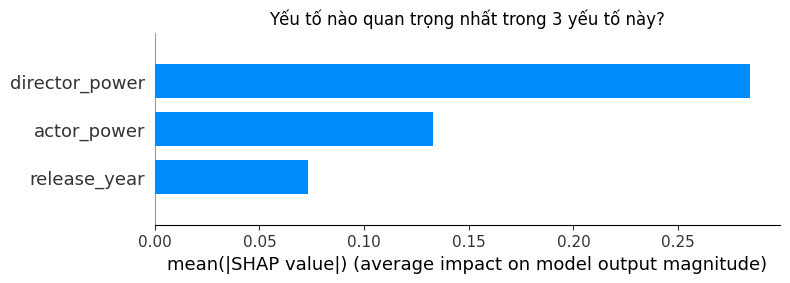

In [139]:
plt.figure(figsize=(10, 5))
shap.summary_plot(shap_values, X, plot_type="bar", show=False)
plt.title("Yếu tố nào quan trọng nhất trong 3 yếu tố này?")
plt.show()

1. Sự thống trị tuyệt đối của Đạo diễn

Các giá trị SHAP cho thấy director_power có mức độ ảnh hưởng vượt trội so với các biến còn lại, đạt khoảng 0.28 — gấp hơn 2,5 lần so với diễn viên và khoảng 5 lần so với năm sản xuất. Kết quả này phản ánh rất đúng bản chất điện ảnh: đạo diễn chính là người định hình chất lượng cuối cùng của bộ phim. Một kịch bản tốt đi kèm đạo diễn yếu có thể trở thành thất bại, trong khi một đạo diễn tài năng vẫn có thể biến các nguồn lực bình thường thành một sản phẩm chất lượng. Vì vậy, trong mô hình dự đoán điểm số, chỉ cần biết ai là đạo diễn đã giúp nâng độ chính xác đáng kể.

2. Vai trò thứ cấp của Diễn viên

Biến actor_power đứng thứ hai với giá trị khoảng 0.12, cho thấy diễn viên nổi tiếng vẫn góp phần nâng điểm phim nhưng không phải yếu tố mang tính quyết định. Nhiều trường hợp phim sở hữu dàn sao lớn nhưng vẫn nhận đánh giá kém khi thiếu sự dẫn dắt tốt từ đạo diễn. Điều này hàm ý rằng diễn viên là yếu tố quan trọng nhưng chỉ mang tính bổ trợ. Khi đạo diễn mạnh, giá trị của diễn viên mới được phát huy trọn vẹn.

3. Ảnh hưởng nhỏ hơn từ Thời gian sản xuất

release_year thể hiện mức độ ảnh hưởng thấp nhất, khoảng 0.05. Mặc dù ở biểu đồ xu hướng trước đó, năm sản xuất có chiều hướng làm giảm điểm phim (đặc biệt ở giai đoạn phim mới), nhưng tác động trung bình chỉ khoảng −0.1 đến −0.2 điểm. So với mức biến động có thể lên tới −1.5 hoặc +0.5 từ đạo diễn, yếu tố thời gian chỉ đóng vai trò điều chỉnh nhỏ. Có thể xem yếu tố năm sản xuất giống như gia vị bổ sung — làm thay đổi nhẹ cảm nhận, nhưng không quyết định chất lượng tổng thể.

Biểu đồ SHAP cho thấy chất lượng phim phụ thuộc chủ yếu vào năng lực đội ngũ sản xuất, đặc biệt là Đạo diễn. Yếu tố thời gian và danh tiếng diễn viên chỉ đóng vai trò bổ trợ.

#### 6. Các phân tích liên quan



##### 6.1 Phân tích "Ma trận Cộng hưởng": Đạo diễn giỏi + Diễn viên giỏi = ?

Phân tích ma trận cộng hưởng cho thấy đạo diễn là yếu tố nền tảng, mang tính quyết định. Vậy, thay vì xem xét riêng lẻ, hãy xem xét sự kết hợp. Liệu một diễn viên ngôi sao có thể "gánh" được một đạo diễn tồi? Hay một đạo diễn tài năng có thể biến diễn viên vô danh thành sao?

a. Phân nhóm theo Phân vị (Quantile Binning)

Thay vì giữ các con số lẻ tẻ (ví dụ: Director Power = 3.45, 4.12...), phương pháp này ép dữ liệu vào 3 giỏ (buckets): Thấp - Trung bình - Cao.

Dùng qcut mà thay vì cut:

+ qcut chia dựa trên số lượng (Quantile). Nó đảm bảo nhóm "Low", "Mid", "High" có số lượng phim bằng nhau.

+ Điều này giúp tránh việc một nhóm nào đó quá ít dữ liệu (ví dụ nhóm "High" chỉ có 2 phim) làm sai lệch kết quả trung bình.

In [140]:
# Chia nhóm (Binning) Power thành 3 mức: Low, Medium, High

full_data['Director_Tier'] = pd.qcut(full_data['director_power'], q=3, labels=['Low', 'Mid', 'High'])

full_data['Actor_Tier'] = pd.qcut(full_data['actor_power'], q=3, labels=['Low', 'Mid', 'High'])



b. Kỹ thuật Bảng chéo (Cross-Tabulation / Pivot Table)

Nguyên lý: Đây là kỹ thuật tạo Ma trận (Matrix). Nó tạo ra một lưới 3x3 (9 ô).

Mục đích: Để xem xét sự giao thoa giữa hai yếu tố. Ví dụ: Tại ô giao nhau giữa Đạo diễn Thấp và Diễn viên Cao, điểm trung bình là bao nhiêu?

In [ ]:
# Tạo bảng Pivot
pivot_table = full_data.pivot_table(index='Director_Tier', columns='Actor_Tier', values='Rating', aggfunc='mean')

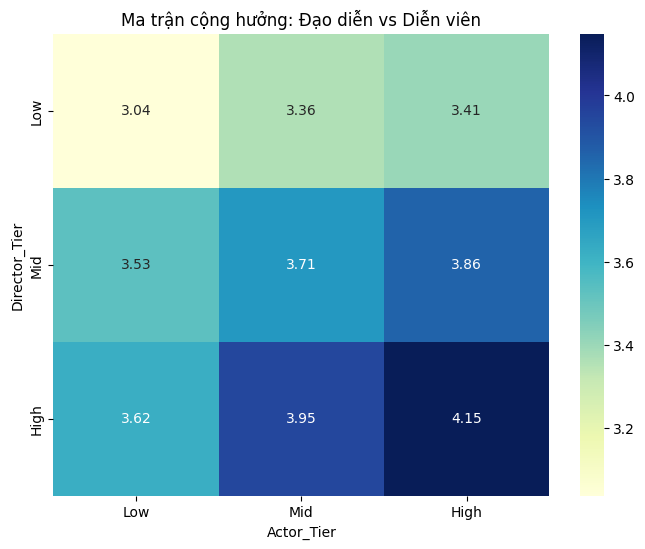

In [142]:
# Vẽ Heatmap

plt.figure(figsize=(8, 6))

sns.heatmap(pivot_table, annot=True, fmt=".2f", cmap="YlGnBu")

plt.title("Ma trận cộng hưởng: Đạo diễn vs Diễn viên")

plt.show()

Biểu đồ cho thấy mối quan hệ tương tác rõ rệt: Đạo diễn nắm vai trò chủ đạo, là người kiến tạo. Một đạo diễn thuộc nhóm High-tier đảm bảo cho bộ phim mức điểm sàn (floor) là 3.62 ngay cả khi không có ngôi sao. Ngược lại, một diễn viên High-tier dù nỗ lực đến đâu cũng chỉ có thể kéo bộ phim của đạo diễn Low-tier lên mức 3.41 (vẫn dưới trung bình).

1. Sự thống trị của Đạo diễn (Director Dominance)

So sánh hai trường hợp lệch pha cho thấy vai trò của đạo diễn vượt trội hoàn toàn so với diễn viên. Khi đạo diễn giỏi nhưng diễn viên yếu (3.62 điểm), bộ phim vẫn được đánh giá cao hơn trường hợp ngược lại: đạo diễn tệ nhưng diễn viên hạng A (3.41 điểm). Điều này khẳng định rằng chất lượng tổng thể của bộ phim phụ thuộc chủ yếu vào năng lực của đạo diễn. Một đạo diễn tài năng có thể nâng tầm cả một dàn diễn viên bình thường, trong khi diễn viên xuất sắc cũng khó cứu nổi một bộ phim nếu đạo diễn yếu kém.

2. Giới hạn của Diễn viên (The "Rescue" Limit)

Khi đạo diễn thuộc nhóm yếu, việc tăng chất lượng diễn viên từ mức thấp (3.04) lên mức cao (3.41) giúp bộ phim cải thiện phần nào, nhưng vẫn không vượt qua được mức trung bình chung của toàn bộ dữ liệu (khoảng 3.6). Điều này cho thấy diễn viên ngôi sao chỉ có thể “cứu” bộ phim khỏi tình trạng tệ hại, nhưng không thể biến một tác phẩm tầm thường thành phim hay nếu nền tảng đạo diễn không vững.

3. Vùng Kiệt tác (The Masterpiece Zone)

Ô kết hợp đạo diễn giỏi và diễn viên giỏi đạt mức điểm 4.15 — con số rất cao trong MovieLens, chỉ xuất hiện ở nhóm phim top đầu. Khi so với trường hợp cả hai cùng yếu (3.04), mức chênh lệch hơn 1.1 điểm là minh chứng cho sự cộng hưởng mạnh mẽ giữa hai yếu tố. Điều này cho thấy để tạo ra một tác phẩm xuất sắc, cần cả sự dẫn dắt tài tình của đạo diễn và phần thể hiện vượt trội từ dàn diễn viên.

##### 6.2. Phân tích "Ngoại lệ" (Outlier Analysis) 

Chúng ta sẽ đi vào tìm hiểu 2 nhóm chính để trả lời cho câu hỏi: "Bộ phim nào có chất lượng sai lệch nhiều nhất so với thương hiệu của người tạo ra nó?"

A. Nhóm “Sa sút”

Đây là những trường hợp đạo diễn nổi tiếng, tay nghề cao nhưng bộ phim lại bị chấm điểm thấp. Điều này có thể xảy ra khi họ làm phim không đúng sở trường, bị can thiệp bởi nhà sản xuất, hoặc đơn giản là phong độ đi xuống. Nhóm này cho thấy: đạo diễn giỏi cũng có lúc làm ra phim dở.

B. Nhóm “Bứt phá”

Nhóm này gồm những đạo diễn ít tiếng tăm hoặc mới vào nghề, nhưng tác phẩm lại được đánh giá rất cao. Đây thường là những phim có kịch bản xuất sắc, ý tưởng độc đáo hoặc là cú “bật lên” hiếm có của một người mới. Điều này khẳng định: không cần nổi tiếng, chỉ cần nội dung hay vẫn có thể tạo nên siêu phẩm.


=== TOP 10 SA SÚT (Gây thất vọng nhất) ===
                       Title         director   Rating  director_power      Diff
            Fair Game (1995)       Doug Liman 2.104167        3.786935 -1.682769
          Mary Reilly (1996)   Stephen Frears 2.340909        3.880931 -1.540022
               Psycho (1998) Alfred Hitchcock 2.651515        3.921470 -1.269955
Beverly Hills Cop III (1994)      John Landis 2.505682        3.747289 -1.241608
     Last Action Hero (1993)   John McTiernan 2.508000        3.684235 -1.176235
                 Hook (1991) Steven Spielberg 3.018006        4.091758 -1.073752
            G.I. Jane (1997)     Ridley Scott 3.052065        4.037769 -0.985704
    Death Becomes Her (1992)  Robert Zemeckis 2.752212        3.728823 -0.976610
               Sphere (1998)   Barry Levinson 2.663586        3.601774 -0.938188
      Renaissance Man (1994)   Penny Marshall 2.870968        3.715354 -0.844386

=== TOP 10 BỨT PHÁ (Gây bất ngờ nhất) ===
               Title  

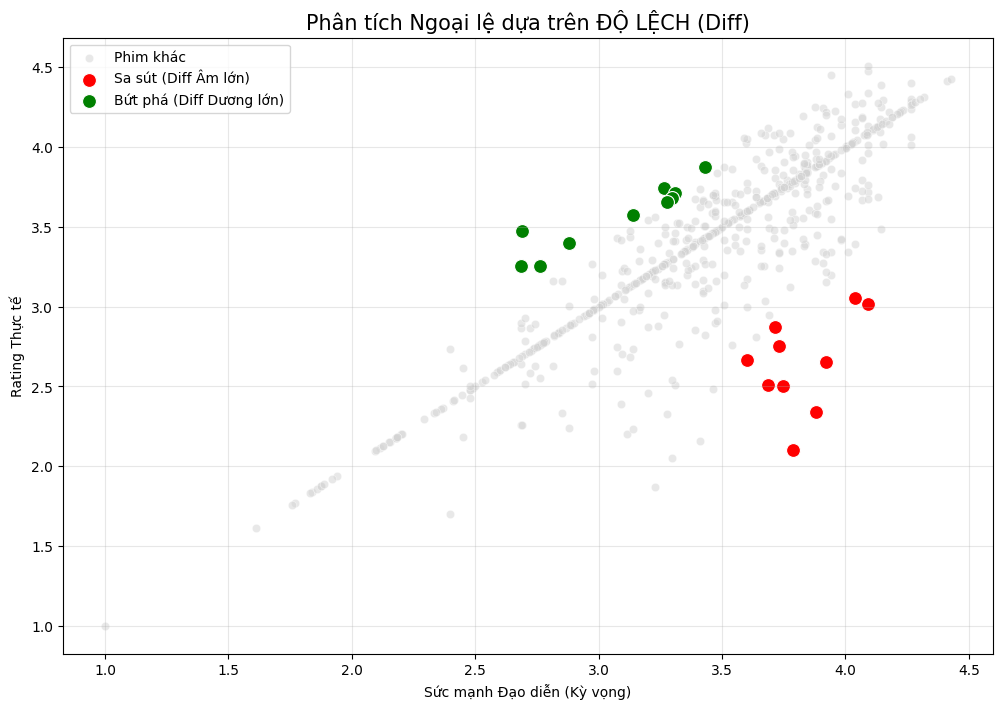

In [152]:
# --- BƯỚC 1: TẠO MOVIE_SUMMARY (KHAI BÁO LẠI CHO CHẮC) ---
# Gom nhóm full_data thành dữ liệu từng phim
movie_summary = full_data.groupby('Title').agg({
    'Rating': 'mean',
    'director_power': 'first',
    'director': 'first',
    'Genres': 'first',
    'release_year': 'first',
    'vote_count': 'first'
}).reset_index()

# Lọc bỏ phim ít vote để tránh nhiễu
movie_summary = movie_summary[movie_summary['vote_count'] > 50]

# --- BƯỚC 2: TÍNH ĐỘ LỆCH (DIFF) ---
# Diff = Rating Thực tế - Kỳ vọng (Power)
movie_summary['Diff'] = movie_summary['Rating'] - movie_summary['director_power']

# --- BƯỚC 3: LỌC BOM XỊT & HIỆN TƯỢNG ---

# 1. Bom xịt: Kỳ vọng cao (Power > 3.5) nhưng Lệch âm lớn nhất (Thực tế kém xa kỳ vọng)
flops = movie_summary[movie_summary['director_power'] > 3.5].sort_values('Diff', ascending=True).head(10)

# 2. Hiện tượng: Kỳ vọng thấp (Power < 3.5) nhưng Lệch dương lớn nhất (Thực tế vượt xa kỳ vọng)
breakouts = movie_summary[movie_summary['director_power'] < 3.5].sort_values('Diff', ascending=False).head(10)

# --- BƯỚC 4: IN KẾT QUẢ ---
cols = ['Title', 'director', 'Rating', 'director_power', 'Diff']

print("\n=== TOP 10 SA SÚT (Gây thất vọng nhất) ===")
print(flops[cols].to_string(index=False))

print("\n=== TOP 10 BỨT PHÁ (Gây bất ngờ nhất) ===")
print(breakouts[cols].to_string(index=False))

# --- BƯỚC 5: TRỰC QUAN HÓA ---
plt.figure(figsize=(12, 8))
# Vẽ nền
sns.scatterplot(data=movie_summary, x='director_power', y='Rating', color='lightgrey', alpha=0.5, label='Phim khác')
# Vẽ Bom xịt
sns.scatterplot(data=flops, x='director_power', y='Rating', color='red', s=100, label='Sa sút (Diff Âm lớn)')
# Vẽ Hiện tượng
sns.scatterplot(data=breakouts, x='director_power', y='Rating', color='green', s=100, label='Bứt phá (Diff Dương lớn)')

plt.title('Phân tích Ngoại lệ dựa trên ĐỘ LỆCH (Diff)', fontsize=15)
plt.xlabel('Sức mạnh Đạo diễn (Kỳ vọng)')
plt.ylabel('Rating Thực tế')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

Dữ liệu về nhóm phim gây thất vọng cho thấy một mô hình rõ rệt: đây đều là các tác phẩm do những đạo diễn có uy tín cao chỉ đạo, nhưng điểm số thực tế lại rơi xuống mức rất thấp. Một phát hiện quan trọng trong nhóm này là trường hợp Psycho (1998), nơi dữ liệu đã ghép nhầm đạo diễn Alfred Hitchcock của bản gốc với bản làm lại năm 1998 của Gus Van Sant. Vì Hitchcock có power gần 4.0, kỳ vọng bị đẩy lên quá cao, trong khi bản remake bị chê dữ dội, dẫn đến sự lệch lớn và bị phân loại là “phim gây thất vọng”. Các ví dụ khác như Hook (Steven Spielberg) hay G.I. Jane (Ridley Scott) cho thấy ngay cả những đạo diễn huyền thoại cũng có thể tạo ra các tác phẩm không đạt kỳ vọng khi thay đổi phong cách hoặc gặp vấn đề trong quá trình sản xuất.

Ở chiều ngược lại, nhóm phim gây bất ngờ tập trung vào các đạo diễn có mức độ uy tín thấp đến trung bình, nhưng tác phẩm của họ lại đạt điểm số cao vượt trội. Bên cạnh đó, nhóm các phim “bất ngờ thật sự” hiện lên rõ nét, đặc biệt trong dòng phim kinh dị như Halloween hay Scream. Đây là những tác phẩm mà các đạo diễn còn ít tên tuổi đã tạo ra dấu ấn mạnh bằng kịch bản độc đáo hoặc phong cách mới mẻ, cho thấy thể loại này có khả năng tạo ra những cú bứt phá ngay cả khi đội ngũ sản xuất chưa có danh tiếng lớn.

Từ hai nhóm đối lập này, có thể đưa ra vài kết luận quan trọng cho báo cáo. Đầu tiên, chỉ số Diff hoạt động chính xác trong việc phát hiện sự lệch giữa kỳ vọng và thực tế, phản ánh đúng tâm lý khán giả: thất vọng không đến từ phim dở mà đến từ phim dở so với danh tiếng đạo diễn. Cuối cùng, kết quả cho thấy chiến lược đầu tư vào các đạo diễn trẻ trong dòng phim kinh dị hoặc hành động có thể mang lại hiệu quả cao, bởi những thể loại này có tỷ lệ xuất hiện “breakout” vượt trội so với các nhóm phim khác.

Phân phối nhãn dự báo:
Fate
2    526
1     61
0     30
Name: count, dtype: int64

Đang huấn luyện mô hình dự báo...

KẾT QUẢ DỰ BÁO:
                    precision    recall  f1-score   support

     Sa sút (Flop)       0.40      0.33      0.36         6
Bứt phá (Breakout)       0.25      0.17      0.20        12
       Bình thường       0.87      0.92      0.89       106

          accuracy                           0.81       124
         macro avg       0.51      0.47      0.49       124
      weighted avg       0.79      0.81      0.80       124



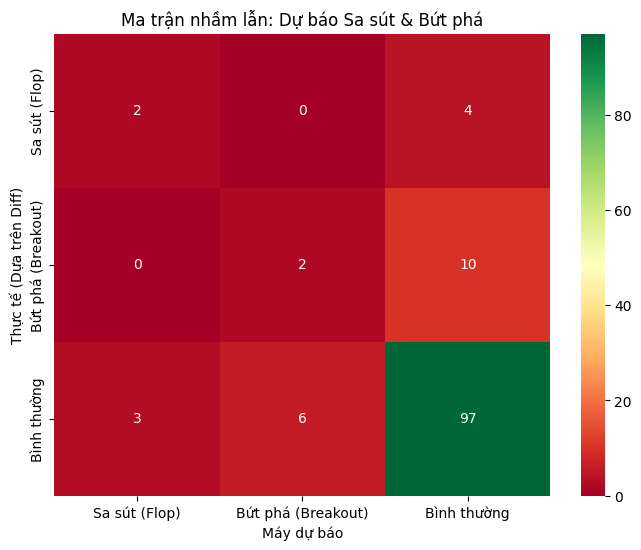

In [153]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# --- BƯỚC 1: TẠO NHÃN (LABELING) DỰA TRÊN LOGIC "ĐỘ LỆCH" (DIFF) ---
# Sử dụng lại movie_summary từ bước trước

# 1. Xác định ngưỡng (Dùng Quantile để linh hoạt)
high_power_thresh = movie_summary['director_power'].quantile(0.80) # Top 20% quyền lực
low_power_thresh = movie_summary['director_power'].quantile(0.50)  # Bottom 50%
diff_low_thresh = movie_summary['Diff'].quantile(0.20)  # Top 20% gây thất vọng nhất
diff_high_thresh = movie_summary['Diff'].quantile(0.80) # Top 20% gây bất ngờ nhất

# 2. Hàm dán nhãn
def get_movie_fate(row):
    # Nhóm Sa sút (Flop): Đạo diễn xịn + Diff Âm lớn
    if (row['director_power'] >= high_power_thresh) and (row['Diff'] <= diff_low_thresh):
        return 0 # Mã 0: SA SÚT
    
    # Nhóm Bứt phá (Breakout): Đạo diễn thường + Diff Dương lớn
    elif (row['director_power'] <= low_power_thresh) and (row['Diff'] >= diff_high_thresh):
        return 1 # Mã 1: BỨT PHÁ
    
    # Còn lại là Bình thường
    else:
        return 2 # Mã 2: BÌNH THƯỜNG

# Áp dụng hàm để tạo cột mục tiêu (Target)
movie_summary['Fate'] = movie_summary.apply(get_movie_fate, axis=1)

print("Phân phối nhãn dự báo:")
print(movie_summary['Fate'].value_counts())
# Bạn sẽ thấy nhóm 0 và 1 khá ít, nhóm 2 chiếm đa số -> Đây là bài toán mất cân bằng dữ liệu

# --- BƯỚC 2: CHUẨN BỊ DỮ LIỆU HUẤN LUYỆN (FEATURES) ---
# Input (X): Chỉ dùng thông tin CÓ TRƯỚC khi phim chiếu
# TUYỆT ĐỐI KHÔNG dùng 'Rating' hay 'Diff' trong X (vì đó là đáp án)
feature_cols = ['director_power', 'release_year'] 
# Nếu bạn có thêm budget hay genres ở movie_summary thì thêm vào đây sẽ tốt hơn

X = movie_summary[feature_cols]
y = movie_summary['Fate']

# Chia tập Train/Test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# --- BƯỚC 3: HUẤN LUYỆN MÔ HÌNH ---
# class_weight='balanced': Cực kỳ quan trọng để máy chú ý vào nhóm thiểu số (Sa sút/Bứt phá)
print("\nĐang huấn luyện mô hình dự báo...")
clf = RandomForestClassifier(n_estimators=200, class_weight='balanced', random_state=42)
clf.fit(X_train, y_train)

# --- BƯỚC 4: ĐÁNH GIÁ & TRỰC QUAN HÓA ---
y_pred = clf.predict(X_test)

# In báo cáo
target_names = ['Sa sút (Flop)', 'Bứt phá (Breakout)', 'Bình thường']
print("\n" + "="*40)
print("KẾT QUẢ DỰ BÁO:")
print("="*40)
print(classification_report(y_test, y_pred, target_names=target_names))

# Vẽ Ma trận nhầm lẫn (Confusion Matrix)
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='RdYlGn', 
            xticklabels=target_names, yticklabels=target_names)
plt.title('Ma trận nhầm lẫn: Dự báo Sa sút & Bứt phá')
plt.ylabel('Thực tế (Dựa trên Diff)')
plt.xlabel('Máy dự báo')
plt.show()

Kết quả mô hình Random Forest phân loại ba nhóm phim (Sa sút – Bứt phá – Bình thường) cho thấy một bức tranh vừa khả quan vừa đầy thách thức. Tuy Accuracy đạt 81%, con số này chủ yếu phản ánh việc mô hình dự đoán rất tốt nhóm Bình thường – vốn chiếm đa số dữ liệu. Vì vậy, độ chính xác tổng thể tạo ra một “ảo ảnh thành công”, và không phản ánh đúng năng lực của mô hình ở hai nhóm quan trọng nhất về mặt kinh doanh: Sa sút và Bứt phá. Do đó, phân tích cần tập trung vào Precision và Recall của từng nhóm thiểu số.

Ở nhóm Sa sút, mô hình có Precision đạt 0.40, tức là cứ mỗi lần mô hình cảnh báo “nguy cơ bom kém hiệu quả”, thì 40% trường hợp là đúng. Đây là một tín hiệu khá tích cực đối với bài toán quản trị rủi ro: mô hình đã có khả năng sàng lọc các trường hợp đáng nghi ngờ để nhà đầu tư chú ý thẩm định sâu hơn. Tuy nhiên, Recall chỉ đạt 0.33, tức mô hình chỉ bắt đúng được 2/6 trường hợp Sa sút thực sự, bỏ sót đến 4 trường hợp khác. Điều này cho thấy mô hình còn yếu trong việc bao phủ đầy đủ các rủi ro tiềm ẩn.

Ở nhóm Bứt phá, mô hình gặp khó khăn lớn hơn. Precision chỉ 0.25 – nghĩa là chỉ 1/4 dự đoán “hiện tượng” là đúng – và Recall lại càng thấp (0.17), bỏ sót hầu hết các trường hợp phim “ngựa ô” thực sự. Điều này phản ánh đúng bản chất của thị trường điện ảnh: việc dự đoán một tác phẩm đột phá từ đạo diễn ít tên tuổi là cực kỳ khó. Số lượng mẫu quá ít và tín hiệu đặc trưng không rõ ràng khiến mô hình khó rút ra quy luật chung.

Nguyên nhân cốt lõi nằm ở sự mất cân bằng dữ liệu nghiêm trọng. Nhóm “Bình thường” có đến 106 mẫu, trong khi nhóm Sa sút chỉ có 6 mẫu và nhóm Bứt phá chỉ 12 mẫu. Mô hình vì vậy học rất tốt các trường hợp phổ biến, nhưng thiếu dữ liệu để hiểu các ngoại lệ – tương tự một học sinh ôn kỹ dạng bài phổ thông nhưng không có đủ ví dụ để giải bài khó.

Tóm lại, mô hình đã chứng minh được tính khả thi ở mức Proof-of-Concept: khả năng tách nhóm dựa trên logic Diff đã có hiệu lực, đặc biệt ở nhóm Sa sút. Tuy nhiên, hạn chế lớn đến từ sự khan hiếm dữ liệu ngoại lệ.

## Kết luận và Trực quan hóa